In [1]:
# -*- coding: utf-8 -*-
"""
@author: Daniel Gunning (University of Bergen)

Template for running an equillibrium simulation of ZEMBA.
"""

# modules
import os
import sys
import pickle
import importlib
import numpy as np
from   numba.core  import types
from   numba.typed import Dict
from   numba       import njit
from   time        import perf_counter
from   numpy       import genfromtxt
from   pathlib     import Path

script_path = Path.cwd().parent
sys.path.insert(0, str(script_path))

# internal modules
from zemba import *
from solar_forcing import *
from initialize_zemba import initialize_state as iz
from initialize_zemba import get_constants as gc

# paths
input_path  = script_path / 'input'
output_path = script_path / 'output'

# -------------
# --- Input ---
# -------------

input_file_name = 'input_equili_pi'

# load
os.chdir(input_path)
file = importlib.import_module(f"{input_file_name}") 
os.chdir(script_path)
name           = file.name                      # simulation name 
input_zemba    = file.input_zemba               # input dictionary           
settings_zemba = file.settings_zemba            # settings dictionary    
version        = file.input_version             # model version   

# ----------------------
# --- Initialization ---
# ----------------------

# load constants
Var = gc(input_zemba)  
    
# initialize model state
iniState = iz(Var, input_zemba) 

# --------------------------
# --- Insolation Forcing ---
# --------------------------

# load orbital parameters
orb = import_orbital_parameters_v2( input_zemba['ikyr'][0] ) 

# insolation forcing
ecc, obl, pre, I, znth_sw, znth_dw = calculate_daily_insolation(orb, Var["latr"], Var["ndays"], day_type = 1)

# --------------------------------------------
# --- Option to fix sea ice and snow cover ---
# --------------------------------------------

res   = input_zemba['res'][0]

# sea ice
if settings_zemba['seaice_flag'] == 1:
    uc = np.arange(1, Var["lat"].size + 1)
    fixed_si_fraction = np.transpose(genfromtxt(f"{output_path}/si_fraction_pi_res{res}.csv",
                                     delimiter=",", skip_header=3, usecols=uc))
    fixed_si_temp     = np.transpose(genfromtxt(f"{output_path}/si_temperature_pi_res{res}.csv",
                                     delimiter=",", skip_header=3, usecols=uc))
else:
    fixed_si_fraction = None
    fixed_si_temp     = None
    
    
# snow cover
if settings_zemba['snowcover_flag'] == 1:
    fixed_sc_fraction = np.transpose(genfromtxt(f"{output_path}/sc_fraction_pi_res{res}.csv",
                                         delimiter=",", skip_header=3, usecols=uc))
else:
    fixed_sc_fraction = None
        
    
# ---------------------
# --- Run the model ---
# ---------------------
 
State, StateYear = run_model(iniState, input_zemba, settings_zemba, Var, I, znth_dw,
                             fixed_si_fraction=fixed_si_fraction, 
                             fixed_si_temp=fixed_si_temp, 
                             fixed_sc_fraction=fixed_sc_fraction)
    

In [8]:
import pandas as pd

FIELD_META = {
    "si_fraction": ("si_fraction",   "sea ice cover"),
    "Tsi":         ("si_temperature","sea ice temperature"),
    "snow_fraction_land":  ("sc_fraction",    "land snow cover"),
    "alpha_land": ("lalbedo",   "land albedo"),
    "alpha_ocean": ("oalbedo",   "ocean albedo"),
}


for field in ["si_fraction", "Tsi", "snow_fraction_land", "alpha_land","alpha_ocean"]:

    fname, desc = FIELD_META[field]

    data = np.asarray(StateYear[field]).T          # (365, nlat) — same as before

    if (fname == "lalbedo"):

        sw  = np.asarray(StateYear['rsds_land'], dtype=float).T

        # insolation-weighted annual mean: sum(alpha * SW) / sum(SW)
        num = np.nansum(data * sw, axis=0)
        den = np.sum(sw, axis=0)
        annual_mean = num / den

    elif (fname == "oalbedo"):

        sw  = np.asarray(StateYear['rsds_ocean'], dtype=float).T

        # insolation-weighted annual mean: sum(alpha * SW) / sum(SW)
        num = np.nansum(data * sw, axis=0)
        den = np.sum(sw, axis=0)
        annual_mean = num / den

    else:

        # replace every day with the annual mean → seasonally flat, same shape
        annual_mean = np.nanmean(data, axis=0)         # (nlat,) mean over days
        
        
    data = np.tile(annual_mean, (data.shape[0], 1))  # (365, nlat) every day = annual mean

    df = pd.DataFrame(data, columns=[str(l) for l in Var["lat"]])
    
    df.insert(0, "Day", np.arange(data.shape[0]))

    header = (f"Seasonal cycle for {desc} taken from the "
              f"pre-industrial simulation of ZEMBA.")

    filepath = f"{input_path}/{fname}_pi_res{input_zemba['res'][0]}.txt"

    with open(filepath, "w", newline="") as f:
        
        f.write(header + "\n\n")                    # description + blank line
        
        df.to_csv(f, index=False, na_rep="")        # NaN (land) -> blank

# Load output

In [2]:
with open( f'{output_path}/output_pi_moist_res1.0.pkl', 'rb') as file:
            pi_01 = pickle.load(file)
with open( f'{output_path}/output_pi_moist_v2_res1.0.pkl', 'rb') as file:
            pi_02 = pickle.load(file)

NameError: name 'output_path' is not defined

# Temperature

###########################
Global Mean Air Temperature
###########################
ZEMBA1: 13.69
ZEMBA2: 13.69
NorESM2: 13.795484644236899
ERA5: 13.724023246348189



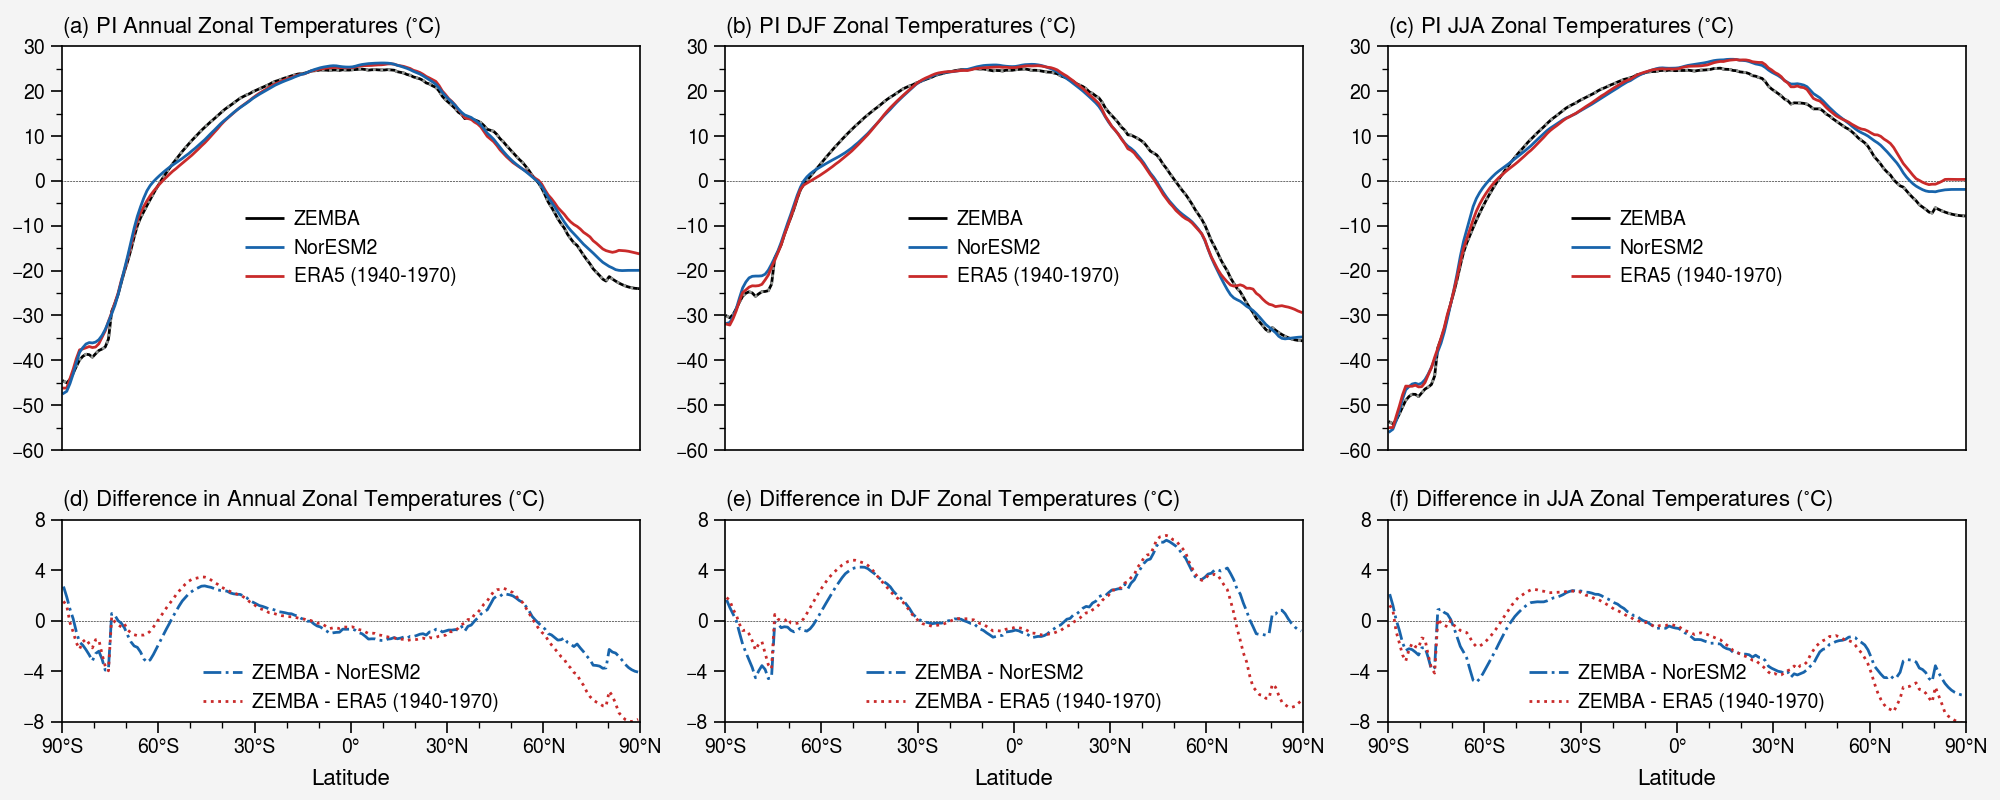

In [4]:
     
# annual-mean surface air temperature
#------------------------------------

zemba_tas_annual1 = pi_01["Tax"].mean(axis=1) - Var["K"]
zemba_tas_global1 = round(global_pymean(zemba_tas_annual1, Var), 2)

zemba_tas_annual2 = pi_02["Tax"].mean(axis=1) - Var["K"]
zemba_tas_global2 = round(global_pymean(zemba_tas_annual2, Var), 2)

# june-july-august mean surface air temperature
#----------------------------------------------

zemba_tas_jja1 = pi_01["Tax"][:,151:242+1].mean(axis=1) - Var["K"] 
zemba_tas_jja2 = pi_02["Tax"][:,151:242+1].mean(axis=1) - Var["K"] 

# december-january-february mean surface air temperature
#-------------------------------------------------------

zemba_tas_djf1 = ((np.append(pi_01["Tax"][:,0:58+1], pi_01["Tax"][:,334:], axis = 1)).mean(axis=1)) - Var["K"] 
zemba_tas_djf2 = ((np.append(pi_02["Tax"][:,0:58+1], pi_02["Tax"][:,334:], axis = 1)).mean(axis=1)) - Var["K"] 

#-----------------------------------
# load pre-industrial NorESM2 output
#-----------------------------------

# load data
noresm2_lat             = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=0)
noresm2_tas_annual      = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=1)
noresm2_tas_monthly_nc  = np.loadtxt(input_path+'/other_data/noresm2/noresm2_t2m_monthly.txt', skiprows=5, usecols=[1,2,3,4,5,6,7,8,9,10,11,12])

# interpolate data
noresm2_tas_annual  = np.interp(Var['lat'], noresm2_lat, noresm2_tas_annual) - Var['K']
noresm2_tas_monthly = np.zeros((Var['lat'].size, 12)) 
for i in np.arange(0,12):
    noresm2_tas_monthly[:,i]=np.interp(Var['lat'], noresm2_lat, noresm2_tas_monthly_nc[:,i])- Var['K']
    
# global_mean 
noresm2_tas_global = global_mean2(noresm2_tas_annual, Var["lat"], Var["dlat"])

# jja mean
noresm2_tas_jja = ( ((noresm2_tas_monthly[:,5]*30.) +
                    (noresm2_tas_monthly[:,6]*31.) +
                    (noresm2_tas_monthly[:,7]*31.))
            
                   /   
                   (30.+31.+31.) ) 

# djf mean
noresm2_tas_djf = ( ((noresm2_tas_monthly[:,11]*31.) +
                     (noresm2_tas_monthly[:,0]*31.) +
                     (noresm2_tas_monthly[:,1]*28.))
                   /
                   (31.+31.+28.) ) 

#-------------------------
# load era5 1940-1970 data
#-------------------------

# load data
era5_lat             = np.loadtxt(input_path+'/other_data/era5/era5_annual.txt', skiprows=5, usecols=0)
era5_tas_annual      = np.loadtxt(input_path+'/other_data/era5/era5_annual.txt', skiprows=5, usecols=1)
era5_tas_monthly_nc  = np.loadtxt(input_path+'/other_data/era5/era5_t2m_monthly.txt', skiprows=5, usecols=[1,2,3,4,5,6,7,8,9,10,11,12])

# interpolate data
era5_tas_annual  = np.interp(Var['lat'], era5_lat, era5_tas_annual) - Var['K']
era5_tas_monthly = np.zeros((Var['lat'].size, 12)) 
for i in np.arange(0,12):
    era5_tas_monthly[:,i]=np.interp(Var['lat'], era5_lat, era5_tas_monthly_nc[:,i]) - Var['K']
    
# global_mean 
era5_tas_global   = global_mean2(era5_tas_annual, Var["lat"], Var["dlat"])

# jja mean
era5_tas_jja = ( ((era5_tas_monthly[:,5]*30.) +
                 (era5_tas_monthly[:,6]*31.) +
                 (era5_tas_monthly[:,7]*31.))
                /
                (30.+31.+31.) ) 

# djf mean
era5_tas_djf = ( ((era5_tas_monthly[:,11]*31.) +
                 (era5_tas_monthly[:,0]*31.) +
                 (era5_tas_monthly[:,1]*28.))
                    /
                (31.+31.+28.) ) 

#---------
# plotting
#---------

# colors and line widths
#-----------------------

zemba_color = "black"
zemba_lw    = 1.
zemba_ls    = "-"

noresm_color = "blue9"
noresm_lw    = 1.
noresm_ls    = "-"

era5_color = "red9"
era5_lw    = 1.
era5_ls    = "-"

zemba_minus_noresm_color = "blue9"
zemba_minus_noresm_lw    = 1.
zemba_minus_noresm_ls    = "-."

zemba_minus_era5_color = "red9"
zemba_minus_era5_lw    = 1.
zemba_minus_era5_ls    = ":"

# legend font size
legend_fs = 7.
legend_fnt = "bold"

# formating
#----------

# shape
shape = [  
        [1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3],
        [1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3],
        [1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3],
        [1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3],
        [4, 4, 4, 4, 5, 5, 5, 5, 6, 6, 6, 6],
        [4, 4, 4, 4, 5, 5, 5, 5, 6, 6, 6, 6],]

# figure and axes
fig, axs = pplt.subplots(shape, figsize = (10,4), sharey = False, sharex = False, grid = False)

# fonts
axs.format(ticklabelsize=7, ticklabelweight='normal', ylabelsize=8, ylabelweight='normal',
            xlabelsize=8, xlabelweight='normal', titlesize=8, titleweight='normal',)

# x-axis
axs.format(xlim = (-90, 90), xlocator = np.arange(-90, 120, 30), xminorlocator = np.arange(-90, 100, 10),)

# format top subplots
for i in np.arange(0,2+1):
    
    # y-axis
    axs[i].format(ylim = (-60, 30), yminorlocator=np.arange(-60, 30, 5), ylocator = np.arange(-60, 30+10, 10))
    
    # hline
    axs[i].axhline(0, Var["lat"].min(), Var["lat"].max(), color = "black", lw = 0.2, linestyle ="--")

    # x-axis
    axs[i].xaxis.set_ticklabels([])
    axs[i].xaxis.set_ticks_position('none')
    axs[i].xaxis.set_tick_params(labelbottom=False)
    
# format bottom subplots  
for i in np.arange(3,5+1):
    
    # y-axis
    axs[i].format(ylim = (-8, 8), yminorlocator=[], ylocator = np.arange(-8, 8+4, 4))
    
    # hline
    axs[i].axhline(0, Var["lat"].min(), Var["lat"].max(), color = "black", lw = 0.2, linestyle ="--")

    # x-axis
    axs[i].format(xlabel = "Latitude", xformatter='deglat')

# titles
axs[0].format(title = r'(a) PI Annual Zonal Temperatures ($^{\circ}$C)',titleloc = 'left')
axs[1].format(title = r'(b) PI DJF Zonal Temperatures ($^{\circ}$C)',titleloc = 'left')
axs[2].format(title = r'(c) PI JJA Zonal Temperatures ($^{\circ}$C)', titleloc = "left")
axs[3].format(title = r'(d) Difference in Annual Zonal Temperatures ($^{\circ}$C)', titleloc = "left")
axs[4].format(title = r'(e) Difference in DJF Zonal Temperatures ($^{\circ}$C)', titleloc = "left")
axs[5].format(title = r'(f) Difference in JJA Zonal Temperatures ($^{\circ}$C)', titleloc = "left")
 

# plot annual mean temperatures
#------------------------------

# lines
zemba_annual_line    = axs[0].plot(Var["lat"], zemba_tas_annual1, color = zemba_color, lw = zemba_lw, linestyle = zemba_ls)
axs[0].plot(Var["lat"], zemba_tas_annual2, color = 'gray', lw = zemba_lw, linestyle = ':')
era5_annual_line   = axs[0].plot(Var["lat"], era5_tas_annual, color = era5_color, lw = era5_lw, linestyle = era5_ls)
noresm_annual_line = axs[0].plot(Var["lat"], noresm2_tas_annual, color = noresm_color, lw = noresm_lw, linestyle = noresm_ls)

# legends
axs[0].legend(handles = [zemba_annual_line, noresm_annual_line, era5_annual_line], labels = ["ZEMBA", "NorESM2", "ERA5 (1940-1970)"], ncols = 1, loc = "c", frameon = False, prop={'size':legend_fs})

# plot differences
zemba_minus_noresm_annual_line = axs[3].plot(Var["lat"], zemba_tas_annual1 - noresm2_tas_annual, color = zemba_minus_noresm_color, lw = zemba_minus_noresm_lw, linestyle = zemba_minus_noresm_ls)
zemba_minus_era5_annual_line   = axs[3].plot(Var["lat"], zemba_tas_annual1 - era5_tas_annual, color = zemba_minus_era5_color, lw = zemba_minus_era5_lw, linestyle = zemba_minus_era5_ls)

# difference legends
axs[3].legend(handles = [zemba_minus_noresm_annual_line, zemba_minus_era5_annual_line], labels = ["ZEMBA - NorESM2", "ZEMBA - ERA5 (1940-1970)"], ncols = 1, loc = "lc", frameon = False, prop={'size':legend_fs})

# plot december - january - february
#-----------------------------------

# lines
zemba_djf_line    = axs[1].plot(Var["lat"], zemba_tas_djf1, color = zemba_color, lw = zemba_lw, linestyle = zemba_ls, alpha = 1)
axs[1].plot(Var["lat"], zemba_tas_djf2, color = 'gray', lw = zemba_lw, linestyle = ':', alpha = 1)
noresm_djf_line = axs[1].plot(Var["lat"], noresm2_tas_djf, color = noresm_color, lw = noresm_lw, linestyle = noresm_ls, alpha = 1)
era5_djf_line   = axs[1].plot(Var["lat"], era5_tas_djf, color = era5_color, lw = era5_lw, linestyle = era5_ls, alpha = 1)
axs[1].legend(handles = [zemba_djf_line, noresm_djf_line, era5_djf_line], labels = ["ZEMBA", "NorESM2", "ERA5 (1940-1970)"], ncols = 1, loc = "c", frameon = False, prop={'size':legend_fs})

# plot difference
zemba_minus_noresm_djf_line = axs[4].plot(Var["lat"], zemba_tas_djf1 - noresm2_tas_djf, color = zemba_minus_noresm_color, lw = zemba_minus_noresm_lw, linestyle = zemba_minus_noresm_ls)
zemba_minus_era5_djf_line   = axs[4].plot(Var["lat"], zemba_tas_djf1 - era5_tas_djf, color = zemba_minus_era5_color, lw = zemba_minus_era5_lw, linestyle = zemba_minus_era5_ls)
axs[4].legend(handles = [zemba_minus_noresm_djf_line, zemba_minus_era5_djf_line, era5_annual_line], labels = ["ZEMBA - NorESM2", "ZEMBA - ERA5 (1940-1970)"], ncols = 1, loc = "lc", frameon = False, prop={'size':legend_fs})

# plot june - july - august
#--------------------------

# lines
zemba_jja_line    = axs[2].plot(Var["lat"], zemba_tas_jja1, color = zemba_color, lw = zemba_lw, linestyle = zemba_ls, alpha = 1)
axs[2].plot(Var["lat"], zemba_tas_jja2, color = 'gray', lw = zemba_lw, linestyle = ':', alpha = 1)
noresm_jja_line = axs[2].plot(Var["lat"], noresm2_tas_jja, color = noresm_color, lw = noresm_lw, linestyle = noresm_ls, alpha = 1)
era5_jja_line   = axs[2].plot(Var["lat"], era5_tas_jja, color = era5_color, lw = era5_lw, linestyle = era5_ls, alpha = 1)
axs[2].legend(handles = [zemba_jja_line, noresm_jja_line, era5_jja_line], labels = ["ZEMBA", "NorESM2", "ERA5 (1940-1970)"], ncols = 1, loc = "c", frameon = False, prop={'size':legend_fs})

# plot difference
zemba_minus_noresm_jja_line = axs[5].plot(Var["lat"], zemba_tas_jja1 - noresm2_tas_jja, color = zemba_minus_noresm_color, lw = zemba_minus_noresm_lw, linestyle = zemba_minus_noresm_ls)
zemba_minus_era5_jja_line   = axs[5].plot(Var["lat"], zemba_tas_jja1 - era5_tas_jja, color = zemba_minus_era5_color, lw = zemba_minus_era5_lw, linestyle = zemba_minus_era5_ls)
leg = axs[5].legend(handles = [zemba_minus_noresm_jja_line, zemba_minus_era5_jja_line, era5_annual_line], labels = ["ZEMBA - NorESM2", "ZEMBA - ERA5 (1940-1970)"], ncols = 1, loc = "lc", frameon = False, prop={'size':legend_fs})

#------------------------------------------------------------------------------
# Print global mean air temperatures
#------------------------------------------------------------------------------

print('###########################')
print('Global Mean Air Temperature')
print('###########################')   
print("ZEMBA1: " + str(zemba_tas_global1))
print("ZEMBA2: " + str(zemba_tas_global2))
print("NorESM2: " + str(noresm2_tas_global))
print("ERA5: " + str(era5_tas_global) + '\n')

# Hydrological

###########################
Global Mean Precipitation....
###########################
Zemba: 2.77
Zemba2: 2.77
NorESM2: 2.85
ERA5: 2.86

###########################
Global Mean Evaporation....
###########################
Zemba1: 2.77
Zemba2: 2.77
NorESM2: 2.85
ERA5: 2.8

###########################
Global Mean Snowfall....
###########################
pyzemba: 0.14
pyzemba2: 0.14
NorESM2: 0.21
ERA5: 0.22



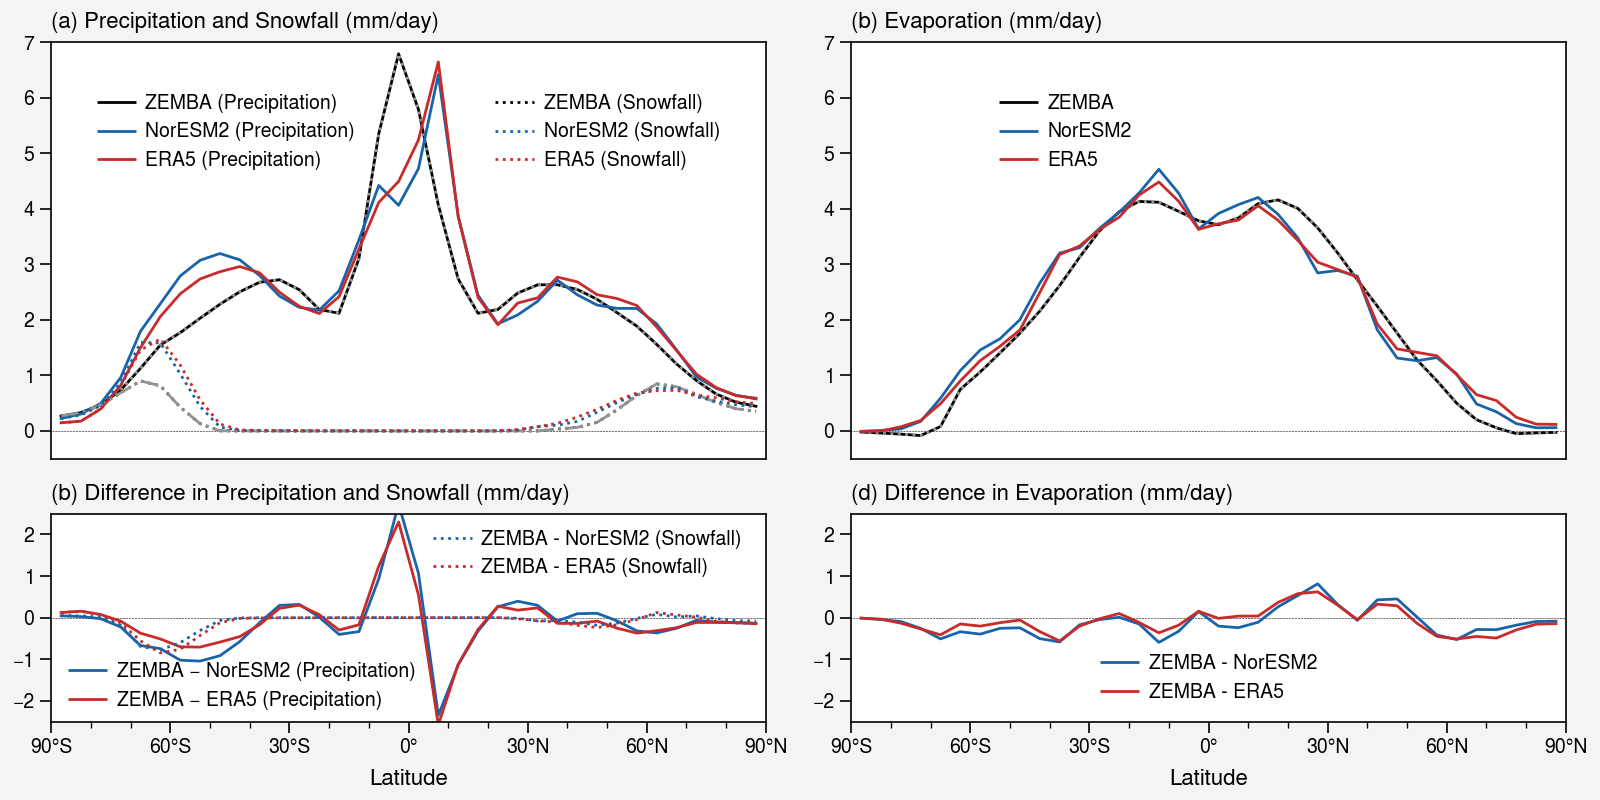

In [5]:
# precipitation
zemba_precip1        = (pi_01['precip_flux'].mean(axis=1)/1000)*(60*60*24)*1000 
zemba_precip_global1 = global_mean2(zemba_precip1, Var1["lat"], Var1["dlat"])

zemba_precip2        = (pi_02['precip_flux'].mean(axis=1)/1000)*(60*60*24)*1000 
zemba_precip_global2 = global_mean2(zemba_precip2, Var2["lat"], Var2["dlat"])

# snowfall
zemba_sf1        = (pi_01['snowfall_flux'].mean(axis=1)/1000)*(60*60*24)*1000  
zemba_sf_global1 = global_mean2(zemba_sf1, Var1["lat"], Var1["dlat"])

zemba_sf2        = (pi_02['snowfall_flux'].mean(axis=1)/1000)*(60*60*24)*1000  
zemba_sf_global2 = global_mean2(zemba_sf2, Var2["lat"], Var2["dlat"])

# evaporation
zemba_evap1        = (pi_01['evap_flux'].mean(axis=1)/1000)*(60*60*24)*1000
zemba_evap_global1 = global_mean2(zemba_evap1, Var1["lat"], Var1["dlat"])

zemba_evap2        = (pi_02['evap_flux'].mean(axis=1)/1000)*(60*60*24)*1000
zemba_evap_global2 = global_mean2(zemba_evap2, Var2["lat"], Var2["dlat"])

#-----------------------------------
# load pre-industrial NorESM2 output
#-----------------------------------

# load annual data
noresm2_lat      = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=0)
noresm2_precip   = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=2)
noresm2_sf       = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=3)
noresm2_evap     = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=4)

# interpolate data
noresm2_precip   = np.interp(Var['lat'], noresm2_lat, noresm2_precip)
noresm2_sf       = np.interp(Var['lat'], noresm2_lat, noresm2_sf)
noresm2_evap     = np.interp(Var['lat'], noresm2_lat, noresm2_evap)

# change from kg m-2 s-1 to mm day-1
noresm2_precip   = noresm2_precip * 1000 * (60*60*24) / 1000
noresm2_sf       = noresm2_sf * 1000 * (60*60*24) / 1000
noresm2_evap     = noresm2_evap * 1000 * (60*60*24) / 1000

# global_mean 
noresm2_precip_global   = global_mean2(noresm2_precip, Var["lat"], Var["dlat"])
noresm2_sf_global       = global_mean2(noresm2_sf, Var["lat"], Var["dlat"])
noresm2_evap_global     = global_mean2(noresm2_evap, Var["lat"], Var["dlat"])


#---------------------------
# ERA5 1940-1970 climatology
#---------------------------

# load annual data
era5_lat      = np.loadtxt(input_path+'/other_data/era5/era5_annual.txt', skiprows=5, usecols=0)
era5_precip   = np.loadtxt(input_path+'/other_data/era5/era5_annual.txt', skiprows=5, usecols=2)
era5_sf       = np.loadtxt(input_path+'/other_data/era5/era5_annual.txt', skiprows=5, usecols=3)
era5_evap     = np.loadtxt(input_path+'/other_data/era5/era5_annual.txt', skiprows=5, usecols=4)

# interpolate data
era5_precip   = np.interp(Var['lat'], era5_lat, era5_precip)
era5_sf       = np.interp(Var['lat'], era5_lat, era5_sf)
era5_evap     = -np.interp(Var['lat'], era5_lat, era5_evap)

# change from kg m-2 s-1 to mm day-1
era5_precip   = era5_precip * 1000 * (60*60*24) / 1000
era5_sf       = era5_sf * 1000 * (60*60*24) / 1000
era5_evap     = era5_evap * 1000 * (60*60*24) / 1000

# global_mean 
era5_precip_global   = global_mean2(era5_precip, Var["lat"], Var["dlat"])
era5_sf_global       = global_mean2(era5_sf, Var["lat"], Var["dlat"])
era5_evap_global     = global_mean2(era5_evap, Var["lat"], Var["dlat"])

#---------
# plotting
#---------

# colors and line widths
#-----------------------

zemba_color = "black"
zemba_lw    = 1.
zemba_ls    = "-"

noresm2_color = "blue9"
noresm2_lw    = 1.
noresm2_ls    = "-"

era5_color = "red9"
era5_lw    = 1.
era5_ls    = "-"

zemba_minus_noresm2_color = "blue9"
zemba_minus_noresm2_lw    = 1.
zemba_minus_noresm2_ls    = "-."

zemba_minus_era5_color = "red9"
zemba_minus_era5_lw    = 1.
zemba_minus_era5_ls    = ":"

legend_fs = 7.

# formating
#----------

# shape
shape = [  
        [1, 1, 1, 1, 2, 2, 2, 2],
        [1, 1, 1, 1, 2, 2, 2, 2],
        [1, 1, 1, 1, 2, 2, 2, 2],
        [1, 1, 1, 1, 2, 2, 2, 2],
        [3, 3, 3, 3, 4, 4, 4, 4],
        [3, 3, 3, 3, 4, 4, 4, 4],]

# figure and axes
fig, axs = pplt.subplots(shape, figsize = (8,4), sharey = False, sharex = False, grid = False)

# fonts
axs.format(ticklabelsize=7, ticklabelweight='normal', ylabelsize=8, ylabelweight='normal',
           xlabelsize=8, xlabelweight='normal', titlesize=8, titleweight='normal',)

# x-axis
locatorx      = np.arange(-90, 120, 30)
minorlocatorx = np.arange(-90, 100, 10)
axs.format(xminorlocator = minorlocatorx, xlocator = locatorx, xlim = (-90, 90))

# format top left subplot
for i in np.arange(0,1):
    
    # y-axis
    axs[i].format(ylim = (-0.5, 7), yminorlocator=[], ylocator = np.arange(0, 7+1, 1))
    
    # hline
    axs[i].axhline(0, Var["lat"].min(), Var["lat"].max(), color = "black", lw = 0.2, linestyle ="--")
    
    # axis
    axs[i].xaxis.set_ticklabels([])
    axs[i].xaxis.set_ticks_position('none')
    axs[i].xaxis.set_tick_params(labelbottom=False)

# format top right subplot
for i in np.arange(1,2):
    
    # y-axis
    axs[i].format(ylim = (-0.5, 7), yminorlocator=[], ylocator = np.arange(0, 7+1, 1))
    
    # hline
    axs[i].axhline(0, Var["lat"].min(), Var["lat"].max(), color = "black", lw = 0.2, linestyle ="--")
    
    # axis
    axs[i].xaxis.set_ticklabels([])
    axs[i].xaxis.set_ticks_position('none')
    axs[i].xaxis.set_tick_params(labelbottom=False)
    
    
# format bottom subplots
for i in np.arange(2,3+1):
    
    # y-axis
    axs[i].format(ylim = (-2.5, 2.5), yminorlocator=[], ylocator = np.arange(-2, 2+1, 1))
    
    # hline
    axs[i].axhline(0, Var["lat"].min(), Var["lat"].max(), color = "black", lw = 0.2, linestyle ="--")
    
    # x-axis
    axs[i].format(xlabel = "Latitude", xformatter='deglat')    

# titles
axs[0].format(title = r'(a) Precipitation and Snowfall (mm/day)', titleloc = 'left')
axs[1].format(title = r'(b) Evaporation (mm/day)', titleloc = 'left')
axs[2].format(title = r'(b) Difference in Precipitation and Snowfall (mm/day)', titleloc = 'left')
axs[3].format(title = r'(d) Difference in Evaporation (mm/day)', titleloc = 'left')

# plot precipitation
#-------------------
zemba_precip_line = axs[0].plot(Var1["lat"], zemba_precip1, color = zemba_color, lw = zemba_lw, linestyle = zemba_ls)
axs[0].plot(Var2["lat"], zemba_precip2, color = 'gray', lw = zemba_lw, linestyle = ':')
noresm2_precip_line = axs[0].plot(Var["lat"], noresm2_precip, color = noresm2_color, lw = noresm2_lw, linestyle = noresm2_ls)
era5_precip_line = axs[0].plot(Var["lat"], era5_precip, color = era5_color, lw = era5_lw, linestyle = era5_ls)
axs[0].legend(handles = [zemba_precip_line, noresm2_precip_line, era5_precip_line],
              labels  = ["ZEMBA (Precipitation)", "NorESM2 (Precipitation)", "ERA5 (Precipitation)"], frameon = False, loc = "ul",
              bbox_to_anchor=(0.05, 0.9), ncols = 1, prop={'size':legend_fs})

# plot differences in precipitation
zemba_minus_noresm_precip = axs[2].plot(Var["lat"], zemba_precip1 - noresm2_precip, color = zemba_minus_noresm2_color, lw = zemba_minus_noresm2_lw, linestyle = "-")
zemba_minus_era5_precip   = axs[2].plot(Var["lat"], zemba_precip1 - era5_precip, color = zemba_minus_era5_color, lw = zemba_minus_era5_lw, linestyle = "-")
axs[2].legend(handles = [zemba_minus_noresm_precip, zemba_minus_era5_precip],
              labels  = ["ZEMBA − NorESM2 (Precipitation)", "ZEMBA − ERA5 (Precipitation) "], frameon = False,  loc = "ll",
               bbox_to_anchor=(0.01, 0.01), ncols = 1, prop={'size':legend_fs})



# plot snowfall
#--------------
zemba_sf_line = axs[0].plot(Var["lat"], zemba_sf1, color = zemba_color, lw = zemba_lw, linestyle = ":", label = ["EBCM"])
axs[0].plot(Var["lat"], zemba_sf2, color = 'gray', lw = zemba_lw, linestyle = "-.", label = ["EBCM"])
noresm2_sf_line = axs[0].plot(Var["lat"], noresm2_sf, color = noresm2_color, lw = noresm2_lw, linestyle = ":", label = ["noresm"])
era5_sf_line = axs[0].plot(Var["lat"], era5_sf, color = era5_color, lw = era5_lw, linestyle = ":", label = ["ERA5 (1940-1970)"])
axs[0].legend(handles = [zemba_sf_line, noresm2_sf_line, era5_sf_line],
              labels  = ["ZEMBA (Snowfall)", "NorESM2 (Snowfall)", "ERA5 (Snowfall)"], frameon = False, loc = "ur",
              bbox_to_anchor=(0.95, 0.9), ncols = 1, prop={'size':legend_fs})

# plot differences in snowfall
zemba_minus_noresm_sf = axs[2].plot(Var["lat"], zemba_sf1 - noresm2_sf, color = zemba_minus_noresm2_color, lw = zemba_minus_noresm2_lw, linestyle = ":")
zemba_minus_era5_sf   = axs[2].plot(Var["lat"], zemba_sf1 - era5_sf, color = zemba_minus_era5_color, lw = zemba_minus_era5_lw, linestyle = ":")
axs[2].legend(handles = [zemba_minus_noresm_sf, zemba_minus_era5_sf],
              labels  = ["ZEMBA - NorESM2 (Snowfall)", "ZEMBA - ERA5 (Snowfall)"], frameon = False,  loc = "ur",
               bbox_to_anchor=(0.98, 0.97), ncols = 1, prop={'size':legend_fs})

# plot evaporation
#------------------
zemba_evap_line = axs[1].plot(Var1["lat"], zemba_evap1, color = zemba_color, lw = zemba_lw, linestyle = zemba_ls, label = ["EBCM"])
axs[1].plot(Var2["lat"], zemba_evap2, color = 'gray', lw = zemba_lw, linestyle = ':', label = ["EBCM"])
noresm2_evap_line = axs[1].plot(Var["lat"], noresm2_evap, color = noresm2_color, lw = noresm2_lw, linestyle = noresm2_ls, label = ["noresm"])
era5_evap_line = axs[1].plot(Var["lat"], era5_evap, color = era5_color, lw = era5_lw, linestyle = era5_ls, label = ["ERA5 (1940-1970)"])
axs[1].legend(handles = [zemba_evap_line, noresm2_evap_line, era5_evap_line],
              labels  = ["ZEMBA", "NorESM2", "ERA5"], frameon = False, loc = "uc",
              bbox_to_anchor=(0.3, 0.9), ncols = 1, prop={'size':legend_fs})

# plot differences in evaporation
zemba_minus_noresm_evap = axs[3].plot(Var["lat"], zemba_evap1 - noresm2_evap, color = zemba_minus_noresm2_color, lw = zemba_minus_noresm2_lw, linestyle = "-")
zemba_minus_era5_evap = axs[3].plot(Var["lat"], zemba_evap1 - era5_evap, color = zemba_minus_era5_color, lw = zemba_minus_era5_lw, linestyle = "-")
axs[3].legend(handles = [zemba_minus_noresm_evap, zemba_minus_era5_evap],
              labels  = ["ZEMBA - NorESM2", "ZEMBA - ERA5"], frameon = False,  loc = "lc",
               bbox_to_anchor=(0.5, 0.05), ncols = 1, prop={'size':legend_fs})

print('###########################')
print("Global Mean Precipitation....")
print('###########################')

print("Zemba: " + str(round(zemba_precip_global1, 2)))

print("Zemba2: " + str(round(zemba_precip_global2, 2)))

print("NorESM2: " + str(round(noresm2_precip_global, 2)))

print("ERA5: " + str(round(era5_precip_global, 2))+'\n')

print('###########################')
print("Global Mean Evaporation....")
print('###########################')

print("Zemba1: " + str(round(zemba_evap_global1, 2)))

print("Zemba2: " + str(round(zemba_evap_global2, 2)))

print("NorESM2: " + str(round(noresm2_evap_global, 2)))

print("ERA5: " + str(round(era5_evap_global, 2))+'\n')

print('###########################')
print("Global Mean Snowfall....")
print('###########################')

print("pyzemba: " + str(round(zemba_sf_global1, 2)))

print("pyzemba2: " + str(round(zemba_sf_global2, 2)))

print("NorESM2: " + str(round(noresm2_sf_global, 2)))

print("ERA5: " + str(round(era5_sf_global, 2))+'\n')

# Albedo

###########################
Planetary Albedo....
###########################
ZEMBA1: 0.31
ZEMBA2: 0.31
NorESM2: 0.3174966900911768
ERA5: 0.3067335038330136

###########################
Surface Albedo....
###########################
ZEMBA1: 0.15
ZEMBA2: 0.15
NorESM2: 0.15094722273312447
ERA5: 0.1576558358490101



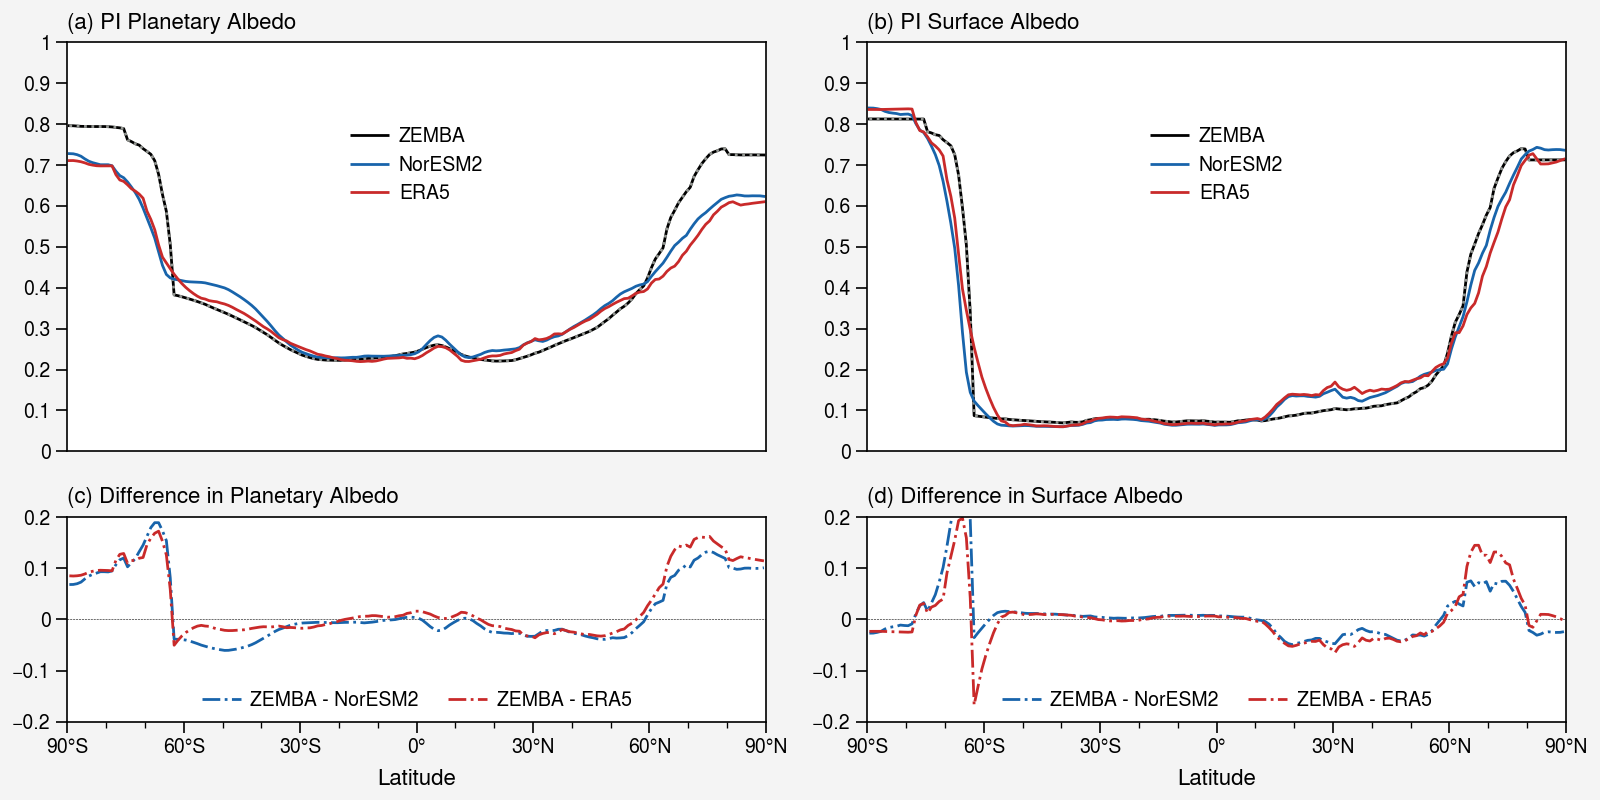

In [5]:
# TOA albedo
zemba_alpha_toa1        = pi_01["rsut"].mean(axis=1)/pi_01["I"].mean(axis=1)
zemba_alpha_toa_global1 = round(global_pymean(zemba_alpha_toa1, Var), 2)

zemba_alpha_toa2        = pi_02["rsut"].mean(axis=1)/pi_01["I"].mean(axis=1)
zemba_alpha_toa_global2 = round(global_pymean(zemba_alpha_toa2, Var), 2)

# BOA albedo
zemba_alpha_boa1        = pi_01["rsus"].mean(axis=1)/pi_01["rsds"].mean(axis=1) 
zemba_alpha_boa_global1 = round(global_pymean(zemba_alpha_boa1, Var), 2)

zemba_alpha_boa2        = pi_02["rsus"].mean(axis=1)/pi_02["rsds"].mean(axis=1) 
zemba_alpha_boa_global2 = round(global_pymean(zemba_alpha_boa2, Var), 2)

#-----------------------------------
# load pre-industrial NorESM2 output
#-----------------------------------

# load annual data
noresm2_lat     = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=0)
noresm2_rsdt    = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=5)
noresm2_rsut    = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=6)
noresm2_rsds    = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=7)
noresm2_rsus    = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=8)

# interpolate data
noresm2_rsdt = np.interp(Var['lat'], noresm2_lat, noresm2_rsdt)
noresm2_rsut = np.interp(Var['lat'], noresm2_lat, noresm2_rsut)
noresm2_rsds = np.interp(Var['lat'], noresm2_lat, noresm2_rsds)
noresm2_rsus = np.interp(Var['lat'], noresm2_lat, noresm2_rsus)

# albedo
noresm2_alphat = noresm2_rsut / noresm2_rsdt
noresm2_alphas = noresm2_rsus / noresm2_rsds

# global_mean 
noresm2_alphat_global = global_mean2(noresm2_alphat, Var["lat"], Var["dlat"])
noresm2_alphas_global = global_mean2(noresm2_alphas, Var["lat"], Var["dlat"])

#---------------------------
# ERA5 1940-1970 climatology
#---------------------------

# load annual data
era5_lat     = np.loadtxt(input_path+'/other_data/era5/era5_annual.txt', skiprows=5, usecols=0)
era5_rsdt    = np.loadtxt(input_path+'/other_data/era5/era5_annual.txt', skiprows=5, usecols=5)
era5_rsut    = np.loadtxt(input_path+'/other_data/era5/era5_annual.txt', skiprows=5, usecols=6)
era5_rsds    = np.loadtxt(input_path+'/other_data/era5/era5_annual.txt', skiprows=5, usecols=7)
era5_rsus    = np.loadtxt(input_path+'/other_data/era5/era5_annual.txt', skiprows=5, usecols=8)

# interpolate data
era5_rsdt = np.interp(Var['lat'], era5_lat, era5_rsdt)
era5_rsut = np.interp(Var['lat'], era5_lat, -era5_rsut)
era5_rsds = np.interp(Var['lat'], era5_lat, era5_rsds)
era5_rsus = np.interp(Var['lat'], era5_lat, era5_rsus)

# albedo
era5_alphat = era5_rsut / era5_rsdt
era5_alphas = era5_rsus / era5_rsds

# global_mean 
era5_alphat_global = global_mean2(era5_alphat, Var["lat"], Var["dlat"])
era5_alphas_global = global_mean2(era5_alphas, Var["lat"], Var["dlat"])

#---------
# plotting
#---------

# constants
#----------

zemba_color = "black"
zemba_lw    = 1.
zemba_ls    = "-"

noresm_color = "blue9"
noresm_lw    = 1.
noresm_ls    = "-"

era5_color = "red9"
era5_lw    = 1.
era5_ls    = "-"

zemba_minus_noresm_color = "blue9"
zemba_minus_noresm_lw    = 1.
zemba_minus_noresm_ls    = "-."

zemba_minus_era5_color = "red9"
zemba_minus_era5_lw    = 1.
zemba_minus_era5_ls    = "-."

legend_fs = 7.
legend_fns = "bold"

# formating
#----------

# shape
shape = [  
        [1, 1, 1, 1, 2, 2, 2, 2],
        [1, 1, 1, 1, 2, 2, 2, 2],
        [1, 1, 1, 1, 2, 2, 2, 2],
        [1, 1, 1, 1, 2, 2, 2, 2],
        [3, 3, 3, 3, 4, 4, 4, 4],
        [3, 3, 3, 3, 4, 4, 4, 4],]

# figure and axes
fig, axs = pplt.subplots(shape, figsize = (8,4), sharey = False, sharex = False, grid = False)

# fonts
axs.format(ticklabelsize=7, ticklabelweight='normal', ylabelsize=8, ylabelweight='normal',
            xlabelsize=8, xlabelweight='normal', titlesize=8, titleweight='normal',)

# x-axis
axs.format(xlim = (-90, 90), xlocator = np.arange(-90, 120, 30), xminorlocator = np.arange(-90, 100, 10),)

# format top subplots
for i in np.arange(0,1+1):
    
    # y-axis
    axs[i].format(ylim = (0, 1), yminorlocator=[], ylocator = np.arange(0, 1+0.1, 0.1))
    
    # hline
    axs[i].axhline(0, Var["lat"].min(), Var["lat"].max(), color = "black", lw = 0.2, linestyle ="--")

    # x-axis
    axs[i].xaxis.set_ticklabels([])
    axs[i].xaxis.set_ticks_position('none')
    axs[i].xaxis.set_tick_params(labelbottom=False)
    
# format bottom subplots  
for i in np.arange(2,3+1):
    
    # y-axis
    axs[i].format(ylim = (-0.2, 0.2), yminorlocator=[], ylocator = np.arange(-0.2, 0.2+0.1, 0.1))
    
    # hline
    axs[i].axhline(0, Var["lat"].min(), Var["lat"].max(), color = "black", lw = 0.2, linestyle ="--")

    # x-axis
    axs[i].format(xlabel = "Latitude", xformatter='deglat')

# titles
axs[0].format(title = r'(a) PI Planetary Albedo',titleloc = 'left')
axs[1].format(title = r'(b) PI Surface Albedo',titleloc = 'left')
axs[2].format(title = r'(c) Difference in Planetary Albedo', titleloc = "left")
axs[3].format(title = r'(d) Difference in Surface Albedo', titleloc = "left")

    
# plot planetary albedo
#----------------------

zemba_toa_line    = axs[0].plot(Var["lat"], zemba_alpha_toa1, color = zemba_color, lw = zemba_lw, linestyle = zemba_ls)
axs[0].plot(Var["lat"], zemba_alpha_toa2, color = 'gray', lw = zemba_lw, linestyle = ':')
noresm_toa_line = axs[0].plot(Var["lat"], noresm2_alphat, color = noresm_color, lw = noresm_lw, linestyle = noresm_ls)
era5_toa_line   = axs[0].plot(Var["lat"], era5_alphat, color = era5_color, lw = era5_lw, linestyle = era5_ls)
axs[0].legend(handles = [zemba_toa_line, noresm_toa_line, era5_toa_line],
              labels  = ["ZEMBA", "NorESM2", "ERA5"], frameon = False,
              loc = "c", bbox_to_anchor=(0.5, 0.7), ncols = 1, prop={'size':legend_fs})

# plot difference in planetary albedo
zemba_minus_noresm_toa_line = axs[2].plot(Var["lat"], zemba_alpha_toa1 - noresm2_alphat, color = zemba_minus_noresm_color, lw = zemba_minus_noresm_lw, linestyle = zemba_minus_noresm_ls)
zemba_minus_era5_toa_line   = axs[2].plot(Var["lat"], zemba_alpha_toa1 - era5_alphat, color = zemba_minus_era5_color, lw = zemba_minus_era5_lw, linestyle = zemba_minus_era5_ls)
axs[2].legend(handles = [zemba_minus_noresm_toa_line, zemba_minus_era5_toa_line],
              labels  = ["ZEMBA - NorESM2", "ZEMBA - ERA5"],
              ncols = 2, loc = "uc", frameon = False, 
              bbox_to_anchor=(0.5, 0.2), prop={'size':legend_fs}) 

# plot surface albedo
#--------------------

zemba_boa_line  = axs[1].plot(Var["lat"], zemba_alpha_boa1, color = zemba_color, lw = zemba_lw, linestyle = zemba_ls, label = ["EBCM"])
axs[1].plot(Var["lat"], zemba_alpha_boa2, color = 'gray', lw = zemba_lw, linestyle = ':', label = ["EBCM"])
noresm_boa_line = axs[1].plot(Var["lat"], noresm2_alphas, color = noresm_color, lw = noresm_lw, linestyle = noresm_ls, label = ["noresm"])
era5_boa_line   = axs[1].plot(Var["lat"], era5_alphas, color = era5_color, lw = era5_lw, linestyle = era5_ls, label = ["ERA5 (1940-1970)"])
axs[1].legend(handles = [zemba_boa_line, noresm_boa_line, era5_boa_line],
              labels  = ["ZEMBA", "NorESM2", "ERA5"], frameon = False,
              loc = "c", bbox_to_anchor=(0.5, 0.7), ncols = 1, prop={'size':legend_fs})

# plot differences in surface albedo
zemba_minus_noresm_boa_line = axs[3].plot(Var["lat"], zemba_alpha_boa1 - noresm2_alphas, color = zemba_minus_noresm_color, lw = zemba_minus_noresm_lw, linestyle = zemba_minus_noresm_ls)
zemba_minus_era5_boa_line   = axs[3].plot(Var["lat"], zemba_alpha_boa1 - era5_alphas, color = zemba_minus_era5_color, lw = zemba_minus_era5_lw, linestyle = zemba_minus_era5_ls)
axs[3].legend(handles = [zemba_minus_noresm_boa_line, zemba_minus_era5_boa_line],
              labels  = ["ZEMBA - NorESM2", "ZEMBA - ERA5"],
              ncols = 2, loc = "uc", frameon = False, 
              bbox_to_anchor=(0.5, 0.2), prop={'size': legend_fs}) 

fig.save(os.getcwd() +"/output/plots/f04.png", dpi= 300)
fig.save(os.getcwd() +"/output/plots/f04.pdf", dpi= 300)

print('###########################')
print("Planetary Albedo....")
print('###########################')
print("ZEMBA1: " + str(zemba_alpha_toa_global1))
print("ZEMBA2: " + str(zemba_alpha_toa_global2))
print("NorESM2: " + str(noresm2_alphat_global))
print("ERA5: " + str(era5_alphat_global) +'\n')


print('###########################')
print("Surface Albedo....")
print('###########################')
print("ZEMBA1: " + str(zemba_alpha_boa_global1))
print("ZEMBA2: " + str(zemba_alpha_boa_global2))
print("NorESM2: " + str(noresm2_alphas_global))
print("ERA5: " + str(era5_alphas_global)+'\n')

# Snow Cover

###########################
Annual Mean Snow Cover
###########################
ZEMBA1 (NH)): 1.74
ZEMBA1 (SH)): 1.37
ZEMBA2 (NH)): 1.74
ZEMBA2 (SH)): 1.37
NorESM2 (NH)): 2.52
NorESM2 (SH)): 1.46
ERA5 (NH)): 2.37
ERA5 (SH)): 1.4

###########################
Annual Mean Sea Ice Cover
###########################
ZEMBA1 (NH)): 1.26
ZEMBA1 (SH)): 1.1
ZEMBA2 (NH)): 1.26
ZEMBA2 (SH)): 1.1
NorESM2 (NH)): 1.15
NorESM2 (SH)): 0.68
ERA5 (NH)): 1.14
ERA5 (SH)): 1.01



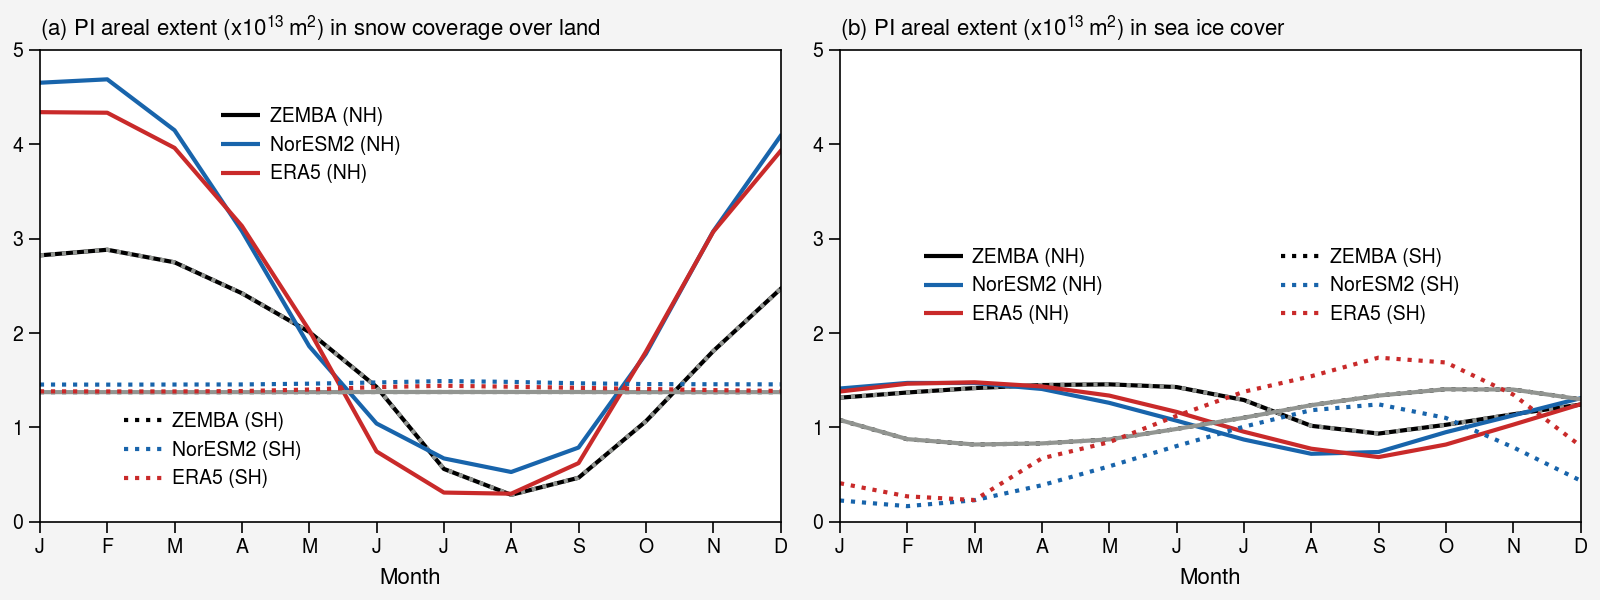

In [6]:
# snow cover (land)
#------------------
 
zemba_snc_monthly1 = calculate_monthlies(pi_01["snow_fraction_land"], Var["lat"].size)
zemba_snc_nh1      = np.nansum(zemba_snc_monthly1[Var["idxnh"].astype("int")]*Var["larea"][Var["idxnh"].astype("int")].reshape(int(Var['lat'].size/2), 1), axis=0)
zemba_snc_sh1      = np.nansum(zemba_snc_monthly1[Var["idxsh"].astype("int")]*Var["larea"][Var["idxsh"].astype("int")].reshape(int(Var['lat'].size/2), 1), axis=0)

zemba_snc_monthly2 = calculate_monthlies(pi_02["snow_fraction_land"], Var["lat"].size)
zemba_snc_nh2      = np.nansum(zemba_snc_monthly2[Var["idxnh"].astype("int")]*Var["larea"][Var["idxnh"].astype("int")].reshape(int(Var['lat'].size/2), 1), axis=0)
zemba_snc_sh2      = np.nansum(zemba_snc_monthly2[Var["idxsh"].astype("int")]*Var["larea"][Var["idxsh"].astype("int")].reshape(int(Var['lat'].size/2), 1), axis=0)


# global
zemba_snc_nh_global1 = np.average(zemba_snc_nh1, weights = Var["days_in_months"])
zemba_snc_sh_global1 = np.average(zemba_snc_sh1, weights = Var["days_in_months"])

zemba_snc_nh_global2 = np.average(zemba_snc_nh2, weights = Var["days_in_months"])
zemba_snc_sh_global2 = np.average(zemba_snc_sh2, weights = Var["days_in_months"])

# sea ice cover
#--------------
zemba_sic_monthly1 = calculate_monthlies(pi_01["si_fraction"], Var["lat"].size)
zemba_sic_nh1 = np.nansum(zemba_sic_monthly1[Var["idxnh"].astype("int")]*Var["oarea"][Var["idxnh"].astype("int")].reshape(int(Var['lat'].size/2), 1), axis=0)
zemba_sic_sh1 = np.nansum(zemba_sic_monthly1[Var["idxsh"].astype("int")]*Var["oarea"][Var["idxsh"].astype("int")].reshape(int(Var['lat'].size/2), 1), axis=0)

zemba_sic_monthly2 = calculate_monthlies(pi_02["si_fraction"], Var["lat"].size)
zemba_sic_nh2 = np.nansum(zemba_sic_monthly2[Var["idxnh"].astype("int")]*Var["oarea"][Var["idxnh"].astype("int")].reshape(int(Var['lat'].size/2), 1), axis=0)
zemba_sic_sh2 = np.nansum(zemba_sic_monthly2[Var["idxsh"].astype("int")]*Var["oarea"][Var["idxsh"].astype("int")].reshape(int(Var['lat'].size/2), 1), axis=0)

# global
zemba_sic_nh_global1 = np.average(zemba_sic_nh1, weights = Var["days_in_months"])
zemba_sic_sh_global1 = np.average(zemba_sic_sh1, weights = Var["days_in_months"])

zemba_sic_nh_global2 = np.average(zemba_sic_nh2, weights = Var["days_in_months"])
zemba_sic_sh_global2 = np.average(zemba_sic_sh2, weights = Var["days_in_months"])
 
#-----------------------------------
# load pre-industrial NorESM2 output
#-----------------------------------

# load annual data
noresm2 = np.loadtxt(input_path+'/other_data/noresm2/noresm2_snc_monthly.txt', skiprows=5, usecols=[1,2,3,4,5,6,7,8,9,10,11,12])
noresm2_sic_nh = noresm2[0,:]*1e12
noresm2_sic_sh = noresm2[1,:]*1e12
noresm2_snc_nh = noresm2[2,:]*1e12
noresm2_snc_sh = noresm2[3,:]*1e12

# global mean
noresm2_sic_nh_global = np.average(noresm2_sic_nh, weights = Var["days_in_months"])
noresm2_sic_sh_global = np.average(noresm2_sic_sh, weights = Var["days_in_months"])
noresm2_snc_nh_global = np.average(noresm2_snc_nh, weights = Var["days_in_months"])
noresm2_snc_sh_global = np.average(noresm2_snc_sh, weights = Var["days_in_months"])

#---------------------------
# ERA5 1940-1970 climatology
#---------------------------

# load annual data
era5 = np.loadtxt(input_path+'/other_data/era5/era5_snc_monthly.txt', skiprows=5, usecols=[1,2,3,4,5,6,7,8,9,10,11,12])
era5_sic_nh = era5[0,:]*1e12
era5_sic_sh = era5[1,:]*1e12
era5_snc_nh = era5[2,:]*1e12
era5_snc_sh = era5[3,:]*1e12 

# global mean
era5_sic_nh_global = np.average(era5_sic_nh, weights = Var["days_in_months"])
era5_sic_sh_global = np.average(era5_sic_sh, weights = Var["days_in_months"])
era5_snc_nh_global = np.average(era5_snc_nh, weights = Var["days_in_months"])
era5_snc_sh_global = np.average(era5_snc_sh, weights = Var["days_in_months"])

#---------
# plotting
#---------

# constants
#----------

zemba_color = "black"
zemba_lw    = 1.
zemba_ls    = "-"

noresm_color = "blue9"
noresm_lw    = 1.
noresm_ls    = "-"

era5_color = "red9"
era5_lw    = 1.
era5_ls    = "-"


# legend font size
legend_fs = 7
legend_fnt = "bold"


# formating
#----------

shape = [  
        [1, 1, 1, 1, 2, 2, 2, 2],
        [1, 1, 1, 1, 2, 2, 2, 2],
        [1, 1, 1, 1, 2, 2, 2, 2],
        [1, 1, 1, 1, 2, 2, 2, 2],]

# figure and axes
fig, axs = pplt.subplots(shape, figsize = (8,3), sharey = False, sharex = False, grid = False)


# fonts
axs.format(ticklabelsize=7, ticklabelweight='normal', ylabelsize=8, ylabelweight='normal',
            xlabelsize=8, xlabelweight='normal', titlesize=8, titleweight='normal',)

# x-axis
axs.format(xlocator = np.arange(1, 12+1), xminorlocator = [], xticklabels = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"],
           xlabel = 'Month')

# format subplots
for i in np.arange(0,1+1):
    
    # y-axis
    axs[i].format(ylim = (0, 5), yminorlocator=np.arange(0, 5+1, 1), ylocator = np.arange(0, 5+1, 1))
    
    # hline
    axs[i].axhline(0, Var["lat"].min(), Var["lat"].max(), color = "black", lw = 0.2, linestyle ="--")
    
# titles
axs[0].format(title = r'(a) PI areal extent (x10$^{13} \: m^{2}$) in snow coverage over land', titleloc = 'left')
axs[1].format(title = r'(b) PI areal extent (x10$^{13} \: m^{2}$) in sea ice cover', titleloc = 'left')


# plot snow cover
#----------------

# northern hemisphere
zemba_snc_nh_line    = axs[0].plot(np.arange(1, 12+1), zemba_snc_nh1/1e13, color = zemba_color, ls = zemba_ls)
axs[0].plot(np.arange(1, 12+1), zemba_snc_nh2/1e13, color = 'gray', ls = ':')
noresm_snc_nh_line = axs[0].plot(np.arange(1, 12+1), noresm2_snc_nh/1e13, color = noresm_color, ls = noresm_ls)
era5_snc_nh_line   = axs[0].plot(np.arange(1, 12+1), era5_snc_nh/1e13, color = era5_color, ls = era5_ls)

# southern hemisphere
zemba_snc_sh_line    = axs[0].plot(np.arange(1, 12+1), zemba_snc_sh1/1e13, color = zemba_color, ls = ":")
axs[0].plot(np.arange(1, 12+1), zemba_snc_sh2/1e13, color = 'gray', ls = "-")
noresm_snc_sh_line = axs[0].plot(np.arange(1, 12+1), noresm2_snc_sh/1e13, color = noresm_color, ls = ":")
era5_snc_sh_line   = axs[0].plot(np.arange(1, 12+1), era5_snc_sh/1e13, color = era5_color, ls = ":")

# sea ice cover
#--------------

# northern hemsphere
zemba_sic_nh_line    = axs[1].plot(np.arange(1, 12+1), zemba_sic_nh1/1e13, color = zemba_color, ls = zemba_ls)
axs[1].plot(np.arange(1, 12+1), zemba_sic_nh2/1e13, color = 'gray', ls = ':')
noresm_sic_nh_line = axs[1].plot(np.arange(1, 12+1), noresm2_sic_nh/1e13, color = noresm_color, ls = noresm_ls)
era5_sic_nh_line   = axs[1].plot(np.arange(1, 12+1), era5_sic_nh/1e13, color = era5_color, ls = era5_ls)

# southern hemisphere
zemba_sic_sh_line    = axs[1].plot(np.arange(1, 12+1), zemba_sic_sh1/1e13, color = zemba_color, ls = ":")
axs[1].plot(np.arange(1, 12+1), zemba_sic_sh2/1e13, color = 'gray', ls = "-")
noresm_sic_sh_line = axs[1].plot(np.arange(1, 12+1), noresm2_sic_sh/1e13, color = noresm_color, ls = ":")
era5_sic_sh_line   = axs[1].plot(np.arange(1, 12+1), era5_sic_sh/1e13, color = era5_color, ls = ":")

# legends
#--------

axs[0].legend(handles = [zemba_snc_nh_line, noresm_snc_nh_line, era5_snc_nh_line], 
              labels = ["ZEMBA (NH)", "NorESM2 (NH)", "ERA5 (NH)"], frameon = False, ncols = 1, 
              loc = "ur", bbox_to_anchor=(0.5, 0.9), prop={'size':legend_fs})

axs[0].legend(handles = [zemba_snc_sh_line, noresm_snc_sh_line, era5_snc_sh_line], 
              labels = ["ZEMBA (SH)", "NorESM2 (SH)", "ERA5 (SH)"], frameon = False, ncols = 1, 
              loc = "ll", bbox_to_anchor=(0.1, 0.05), prop={'size':legend_fs})


axs[1].legend(handles = [zemba_sic_nh_line, noresm_sic_nh_line, era5_sic_nh_line], 
              labels = ["ZEMBA (NH)", "NorESM2 (NH)", "ERA5 (NH)"], frameon = False, ncols = 1, 
              loc = "cl", bbox_to_anchor=(0.1, 0.5), prop={'size':legend_fs})

axs[1].legend(handles = [zemba_sic_sh_line, noresm_sic_sh_line, era5_sic_sh_line], 
              labels = ["ZEMBA (SH)", "NorESM2 (SH)", "ERA5 (SH)"], frameon = False, ncols = 1, 
              loc = "cr", bbox_to_anchor=(0.85, 0.5), prop={'size':legend_fs})


print('###########################')
print("Annual Mean Snow Cover")
print('###########################')

print("ZEMBA1 (NH)): " + str(round(zemba_snc_nh_global1/1e13, 2)))
print("ZEMBA1 (SH)): " + str(round(zemba_snc_sh_global1/1e13, 2)))

print("ZEMBA2 (NH)): " + str(round(zemba_snc_nh_global2/1e13, 2)))
print("ZEMBA2 (SH)): " + str(round(zemba_snc_sh_global2/1e13, 2)))

print("NorESM2 (NH)): " + str(round(noresm2_snc_nh_global/1e13, 2)))
print("NorESM2 (SH)): " + str(round(noresm2_snc_sh_global/1e13, 2)))

print("ERA5 (NH)): " + str(round(era5_snc_nh_global/1e13, 2)))
print("ERA5 (SH)): " + str(round(era5_snc_sh_global/1e13, 2))+'\n')

print('###########################')
print("Annual Mean Sea Ice Cover")
print('###########################')

print("ZEMBA1 (NH)): " + str(round(zemba_sic_nh_global1/1e13, 2)))
print("ZEMBA1 (SH)): " + str(round(zemba_sic_sh_global1/1e13, 2)))

print("ZEMBA2 (NH)): " + str(round(zemba_sic_nh_global2/1e13, 2)))
print("ZEMBA2 (SH)): " + str(round(zemba_sic_sh_global2/1e13, 2)))

print("NorESM2 (NH)): " + str(round(noresm2_sic_nh_global/1e13, 2)))
print("NorESM2 (SH)): " + str(round(noresm2_sic_sh_global/1e13, 2)))

print("ERA5 (NH)): " + str(round(era5_sic_nh_global/1e13, 2)))
print("ERA5 (SH)): " + str(round(era5_sic_sh_global/1e13, 2))+'\n')

# Radiation

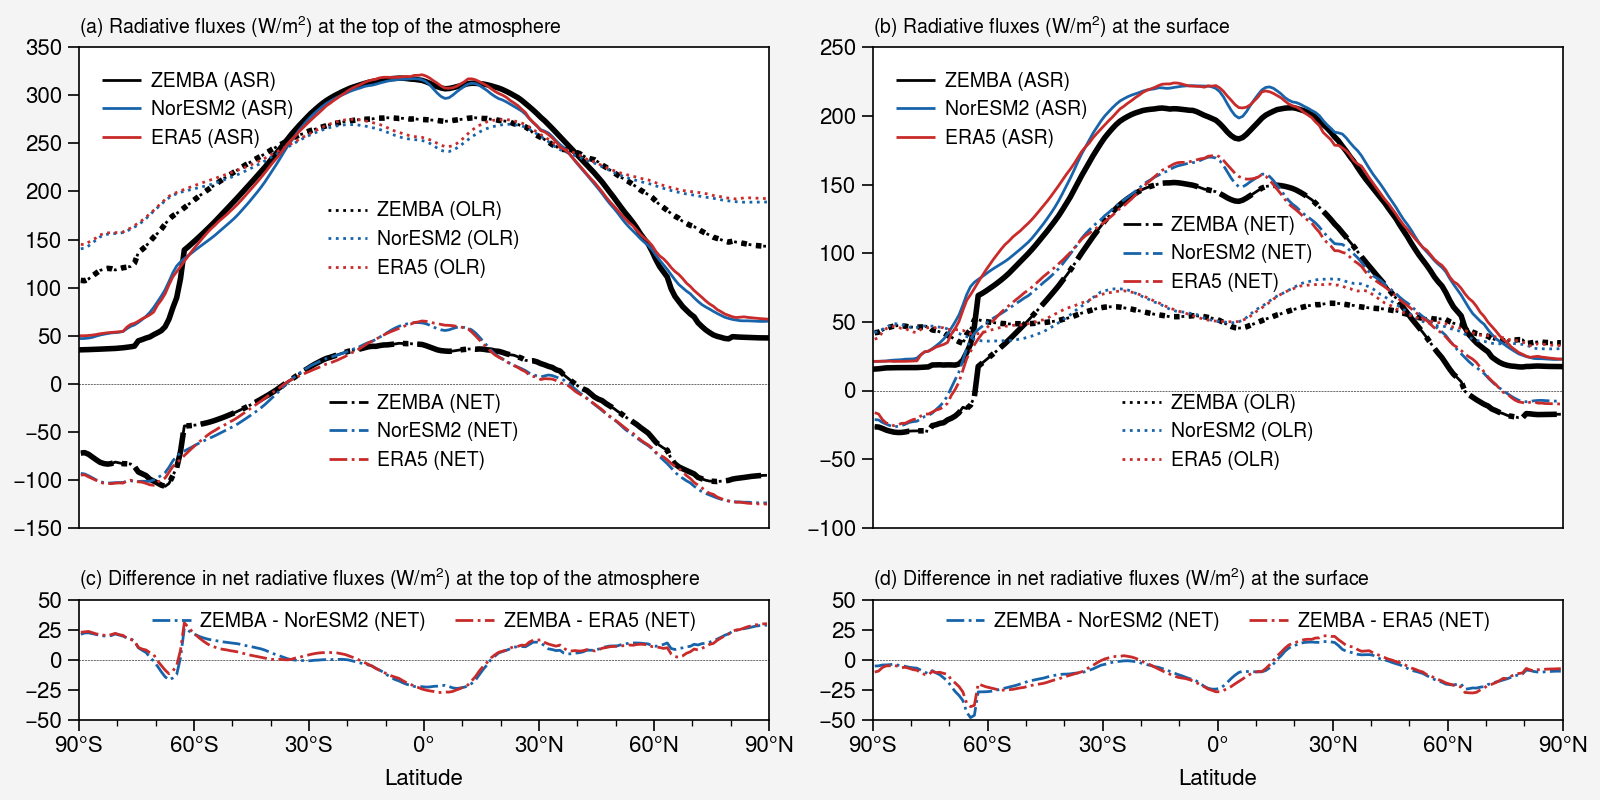

In [7]:

# radiative fluxes
#-----------------
zemba_rsdtnet1 = pi_01['rsdtnet'].mean(axis=1)  # TOA net shortwave
zemba_rlut1    = pi_01['rlut'].mean(axis=1)     # TOA outgoing longwave
zemba_rtnet1   = pi_01['rtnet'].mean(axis=1)    # TOA net total radiation
zemba_rsdsnet1 = pi_01['rsdsnet'].mean(axis=1)  # BOA net shortwave
zemba_rlus1    = -pi_01['rldsnet'].mean(axis=1) # BOA net outgoing longwave
zemba_rsnet1   = pi_01['rsnet'].mean(axis=1)    # BOA net total radiation

zemba_rsdtnet2 = pi_02['rsdtnet'].mean(axis=1)  # TOA net shortwave
zemba_rlut2    = pi_02['rlut'].mean(axis=1)     # TOA outgoing longwave
zemba_rtnet2   = pi_02['rtnet'].mean(axis=1)    # TOA net total radiation
zemba_rsdsnet2 = pi_02['rsdsnet'].mean(axis=1)  # BOA net shortwave
zemba_rlus2    = -pi_02['rldsnet'].mean(axis=1) # BOA net outgoing longwave
zemba_rsnet2   = pi_02['rsnet'].mean(axis=1)    # BOA net total radiation

# global
zemba_rtnet_global1   = global_mean2(zemba_rtnet1, Var["lat"], Var["dlat"])  
zemba_rsnet_global1   = global_mean2(zemba_rsnet1, Var["lat"], Var["dlat"])

zemba_rtnet_global2   = global_mean2(zemba_rtnet2, Var["lat"], Var["dlat"])  
zemba_rsnet_global2   = global_mean2(zemba_rsnet2, Var["lat"], Var["dlat"]) 

#-----------------------------------
# load pre-industrial NorESM2 output
#-----------------------------------

# load annual data
noresm2_lat     = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=0)
noresm2_rsdt    = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=5)
noresm2_rsut    = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=6)
noresm2_rsds    = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=7)
noresm2_rsus    = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=8)
noresm2_rlut    = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=9)
noresm2_rlds    = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=10)
noresm2_rlus    = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=11)

# interpolate data
noresm2_rsdt = np.interp(Var['lat'], noresm2_lat, noresm2_rsdt)
noresm2_rsut = np.interp(Var['lat'], noresm2_lat, noresm2_rsut)
noresm2_rsds = np.interp(Var['lat'], noresm2_lat, noresm2_rsds)
noresm2_rsus = np.interp(Var['lat'], noresm2_lat, noresm2_rsus)
noresm2_rlut = np.interp(Var['lat'], noresm2_lat, noresm2_rlut)
noresm2_rlds = np.interp(Var['lat'], noresm2_lat, noresm2_rlds)
noresm2_rlus = np.interp(Var['lat'], noresm2_lat, noresm2_rlus)

# net shortwave
noresm2_rsdtnet = noresm2_rsdt - noresm2_rsut
noresm2_rsdsnet = noresm2_rsds - noresm2_rsus

# net longwave
noresm2_rldsnet = noresm2_rlds - noresm2_rlus

# net total
noresm2_rtnet = noresm2_rsdtnet - noresm2_rlut
noresm2_rsnet = noresm2_rsdsnet + noresm2_rldsnet

#---------------------------
# ERA5 1940-1970 climatology
#---------------------------

era5_lat     = np.loadtxt(input_path+'/other_data/era5/era5_annual.txt', skiprows=5, usecols=0)
era5_rsdt    = np.loadtxt(input_path+'/other_data/era5/era5_annual.txt', skiprows=5, usecols=5)
era5_rsut    = np.loadtxt(input_path+'/other_data/era5/era5_annual.txt', skiprows=5, usecols=6)
era5_rsds    = np.loadtxt(input_path+'/other_data/era5/era5_annual.txt', skiprows=5, usecols=7)
era5_rsus    = np.loadtxt(input_path+'/other_data/era5/era5_annual.txt', skiprows=5, usecols=8)
era5_rlut    = np.loadtxt(input_path+'/other_data/era5/era5_annual.txt', skiprows=5, usecols=9)
era5_rlds    = np.loadtxt(input_path+'/other_data/era5/era5_annual.txt', skiprows=5, usecols=10)
era5_rlus    = np.loadtxt(input_path+'/other_data/era5/era5_annual.txt', skiprows=5, usecols=11)

# interpolate data
era5_rsdt = np.interp(Var['lat'], era5_lat, era5_rsdt)
era5_rsut = np.interp(Var['lat'], era5_lat, -era5_rsut)
era5_rsds = np.interp(Var['lat'], era5_lat, era5_rsds)
era5_rsus = np.interp(Var['lat'], era5_lat, era5_rsus)
era5_rlut = np.interp(Var['lat'], era5_lat, -era5_rlut)
era5_rlds = np.interp(Var['lat'], era5_lat, era5_rlds)
era5_rlus = np.interp(Var['lat'], era5_lat, era5_rlus)

# net shortwave
era5_rsdtnet = era5_rsdt - era5_rsut
era5_rsdsnet = era5_rsds - era5_rsus

# net longwave
era5_rldsnet = era5_rlds - era5_rlus

# net total
era5_rtnet = era5_rsdtnet - era5_rlut
era5_rsnet = era5_rsdsnet + era5_rldsnet

#---------
# plotting
#---------

# constants
#----------

zemba_color = "black"
zemba_lw    = 1

noresm_color = "blue9"
noresm_lw    = 1

era5_color = "red9"
era5_lw    = 1

zemba_minus_noresm_color = "blue9"
zemba_minus_noresm_lw    = 1
zemba_minus_noresm_ls    = "-."

zemba_minus_era5_color = "red9"
zemba_minus_era5_lw    = 1
zemba_minus_era5_ls    = "-."

zemba_ls = "-"
noresm_ls = ":"
era5_ls = "-."

asr_ls = "-"
olw_ls = ":"
net_ls = "-."

legend_fs=7.

# formating
#----------

shape = [  
        [1, 1, 1, 1, 2, 2, 2, 2],
        [1, 1, 1, 1, 2, 2, 2, 2],
        [1, 1, 1, 1, 2, 2, 2, 2],
        [1, 1, 1, 1, 2, 2, 2, 2],
        [3, 3, 3, 3, 4, 4, 4, 4],]

# figure and axes
fig, axs = pplt.subplots(shape, figsize = (8,4), sharey = False, sharex = False, grid = False)


# fonts
axs.format(ticklabelsize=8., ticklabelweight='normal', ylabelsize=8, ylabelweight='normal',
           xlabelsize=8, xlabelweight='normal', titlesize=7, titleweight='normal',)

# x-axis
locatorx      = np.arange(-90, 120, 30)
minorlocatorx = np.arange(-90, 100, 10)
axs.format(xminorlocator = minorlocatorx, xlocator = locatorx, xlim = (-90, 90))

# format top left subplot
for i in np.arange(0,1):
    
    # y-axis
    axs[i].format(ylim = (-150, 350), yminorlocator=[], ylocator = np.arange(-150, 350+50, 50))
    
    # hline
    axs[i].axhline(0, Var["lat"].min(), Var["lat"].max(), color = "black", lw = 0.2, linestyle ="--")
    
    # x-axis
    axs[i].xaxis.set_ticklabels([])
    axs[i].xaxis.set_ticks_position('none')
    axs[i].xaxis.set_tick_params(labelbottom=False)

# format top right subplot
for i in np.arange(1,2):
    
    # y-axis
    axs[i].format(ylim = (-100, 250), yminorlocator=[], ylocator = np.arange(-100, 250+50, 50))
    
    # hline
    axs[i].axhline(0, Var["lat"].min(), Var["lat"].max(), color = "black", lw = 0.2, linestyle ="--")
    
    # x-axis
    axs[i].xaxis.set_ticklabels([])
    axs[i].xaxis.set_ticks_position('none')
    axs[i].xaxis.set_tick_params(labelbottom=False)
    
# format bottom subplots
for i in np.arange(2,3+1):
    
    # y-axis
    axs[i].format(ylim = (-50, 50), yminorlocator=[], ylocator = np.arange(-50, 50+25, 25))
    
    # hline
    axs[i].axhline(0, Var["lat"].min(), Var["lat"].max(), color = "black", lw = 0.2, linestyle ="--")
    
    # x-axis
    axs[i].format(xlabel = "Latitude", xformatter='deglat')
    
# titles
axs[0].format(title = r'(a) Radiative fluxes ($W/m^{2}$) at the top of the atmosphere', titleloc = 'left')
axs[1].format(title = r'(b) Radiative fluxes ($W/m^{2}$) at the surface', titleloc = 'left')
axs[2].format(title = r'(c) Difference in net radiative fluxes ($W/m^{2}$) at the top of the atmosphere', titleloc = 'left')
axs[3].format(title = r'(d) Difference in net radiative fluxes ($W/m^{2}$) at the surface', titleloc = 'left')
 
# plot TOA radiative fluxes
#--------------------------

zemba_toa_asr = axs[0].plot(Var["lat"], zemba_rsdtnet1, color = zemba_color, lw = zemba_lw, ls = asr_ls) # Net shortwave at TOA
zemba_toa_olw = axs[0].plot(Var["lat"], zemba_rlut1, color = zemba_color, lw = zemba_lw, ls = olw_ls)   # Outgoing longwave radiation at TOA
zemba_toa_net = axs[0].plot(Var["lat"], zemba_rtnet1, color = zemba_color, lw = zemba_lw, ls = net_ls)   # Net radiation at TOA

axs[0].plot(Var["lat"], zemba_rsdtnet2, color = zemba_color, lw = 2, ls = asr_ls) # Net shortwave at TOA
axs[0].plot(Var["lat"], zemba_rlut2, color = zemba_color, lw = 2, ls = olw_ls)   # Outgoing longwave radiation at TOA
axs[0].plot(Var["lat"], zemba_rtnet2, color = zemba_color, lw = 2, ls = net_ls)   # Net radiation at TOA


noresm_toa_asr = axs[0,0].plot(Var["lat"], noresm2_rsdtnet, color = noresm_color, lw = noresm_lw, ls = asr_ls)  # Net shortwave at TOA
noresm_toa_olw = axs[0,0].plot(Var["lat"], noresm2_rlut, color = noresm_color, lw = noresm_lw, ls = olw_ls)     # Outgoing longwave radiation at TOA
noresm_toa_net = axs[0,0].plot(Var["lat"], noresm2_rtnet, color = noresm_color, lw = noresm_lw, ls = net_ls)     # Net radiation at TOA

era5_toa_asr = axs[0,0].plot(Var["lat"], era5_rsdtnet, color = era5_color, lw = era5_lw, ls = asr_ls)  # Net shortwave at TOA
era5_toa_olw = axs[0,0].plot(Var["lat"], era5_rlut, color = era5_color, lw = era5_lw, ls = olw_ls)      # Outgoing longwave radiation at TOA
era5_toa_net = axs[0,0].plot(Var["lat"], era5_rtnet, color = era5_color, lw = era5_lw, ls = net_ls)     # Net radiation at TOA

# legends
axs[0].legend(handles = [zemba_toa_asr, noresm_toa_asr, era5_toa_asr],
              labels  = ["ZEMBA (ASR)", "NorESM2 (ASR)", "ERA5 (ASR)"], frameon = False,
              loc = "ul", bbox_to_anchor=(0.02, 0.97), ncols = 1, prop={'size':legend_fs})  

axs[0].legend(handles = [zemba_toa_olw, noresm_toa_olw, era5_toa_olw],
              labels  = ["ZEMBA (OLR)", "NorESM2 (OLR)", "ERA5 (OLR)"], frameon = False,
              loc = "c", bbox_to_anchor=(0.5, 0.6), ncols = 1, prop={'size':legend_fs})   

axs[0].legend(handles = [zemba_toa_net, noresm_toa_net, era5_toa_net],
              labels  = ["ZEMBA (NET)", "NorESM2 (NET)", "ERA5 (NET)"], frameon = False,
              loc = "lc", bbox_to_anchor=(0.5, 0.1), ncols = 1, prop={'size':legend_fs})  

# plot difference in net radiative fluxes at TOA
#-----------------------------------------------

zemba_minus_noresm_toa_line = axs[2].plot(Var["lat"],  zemba_rtnet1 - noresm2_rtnet, color = zemba_minus_noresm_color, ls = zemba_minus_noresm_ls, lw = zemba_minus_noresm_lw)
zemba_minus_era5_toa_line = axs[2].plot(Var["lat"],  zemba_rtnet1 - era5_rtnet, color = zemba_minus_era5_color, ls = zemba_minus_era5_ls, lw = zemba_minus_era5_lw)

# legend
axs[2].legend(handles = [zemba_minus_noresm_toa_line, zemba_minus_era5_toa_line],
              labels  = ["ZEMBA - NorESM2 (NET)", "ZEMBA - ERA5 (NET)"], frameon = False,
              loc = "uc", bbox_to_anchor=(0.5, 0.98), ncols = 2, prop={'size':legend_fs}) 

# plot SFC radiative fluxes
#--------------------------

zemba_boa_asr = axs[1].plot(Var["lat"], zemba_rsdsnet1, color = zemba_color, lw = zemba_lw, ls = asr_ls) # Net shortwave at boa
zemba_boa_olw = axs[1].plot(Var["lat"], zemba_rlus1, color = zemba_color, lw = zemba_lw, ls = olw_ls)     # Outgoing longwave radiation at boa
zemba_boa_net = axs[1].plot(Var["lat"], zemba_rsnet1, color = zemba_color, lw = zemba_lw, ls = net_ls)   # Net radiation at boa

axs[1].plot(Var["lat"], zemba_rsdsnet2, color = zemba_color, lw = 2, ls = asr_ls) # Net shortwave at boa
axs[1].plot(Var["lat"], zemba_rlus2, color = zemba_color, lw = 2, ls = olw_ls)     # Outgoing longwave radiation at boa
axs[1].plot(Var["lat"], zemba_rsnet2, color = zemba_color, lw = 2, ls = net_ls)   # Net radiation at boa


noresm_boa_asr = axs[1].plot(Var["lat"], noresm2_rsdsnet, color = noresm_color, lw = noresm_lw, ls = asr_ls) # Net shortwave at boa
noresm_boa_olw = axs[1].plot(Var["lat"], noresm2_rlus-noresm2_rlds, color = noresm_color, lw = noresm_lw, ls = olw_ls)     # Outgoing longwave radiation at boa
noresm_boa_net = axs[1].plot(Var["lat"], noresm2_rsnet, color = noresm_color, lw = noresm_lw, ls = net_ls)    # Net radiation at boa

era5_boa_asr = axs[1].plot(Var["lat"], era5_rsdsnet, color = era5_color, lw = era5_lw, ls = asr_ls)  # Net shortwave at boa
era5_boa_olw = axs[1].plot(Var["lat"], era5_rlus-era5_rlds, color = era5_color, lw = era5_lw, ls = olw_ls)     # Outgoing longwave radiation at boa
era5_boa_net = axs[1].plot(Var["lat"], era5_rsnet, color = era5_color, lw = era5_lw, ls = net_ls)   # Net radiation at boa

# legend
axs[1].legend(handles = [zemba_boa_asr, noresm_boa_asr, era5_boa_asr],
              labels  = ["ZEMBA (ASR)", "NorESM2 (ASR)", "ERA5 (ASR)"], frameon = False,
              loc = "ul", bbox_to_anchor=(0.02, 0.97), ncols = 1, prop={'size':legend_fs})  

axs[1].legend(handles = [zemba_boa_olw, noresm_boa_olw, era5_boa_olw],
              labels  = ["ZEMBA (OLR)", "NorESM2 (OLR)", "ERA5 (OLR)"], frameon = False,
              loc = "lc", bbox_to_anchor=(0.5, 0.1), ncols = 1, prop={'size':legend_fs}) 


axs[1].legend(handles = [zemba_boa_net, noresm_boa_net, era5_boa_net],
              labels  = ["ZEMBA (NET)", "NorESM2 (NET)", "ERA5 (NET)"], frameon = False,
              loc = "c", bbox_to_anchor=(0.5, 0.57), ncols = 1, prop={'size':legend_fs}) 


# plot difference in net radiative fluxes at surface
#----------------------------------------------------

zemba_minus_noresm_sfc_line = axs[3].plot(Var["lat"],  zemba_rsnet1 - noresm2_rsnet, color = zemba_minus_noresm_color, ls = zemba_minus_noresm_ls, lw = zemba_minus_noresm_lw)
zemba_minus_era5_sfc_line = axs[3].plot(Var["lat"],  zemba_rsnet1 - era5_rsnet, color = zemba_minus_era5_color, ls = zemba_minus_era5_ls, lw = zemba_minus_era5_lw)

# legend
axs[3].legend(handles = [zemba_minus_noresm_sfc_line, zemba_minus_era5_sfc_line],
              labels  = ["ZEMBA - NorESM2 (NET)", "ZEMBA - ERA5 (NET)"], frameon = False,
              loc = "uc", bbox_to_anchor=(0.5, 0.98), ncols = 2, prop={'size':legend_fs})  

# Heat Transport

###########################
Peak Atmospheric Heat Transport....
###########################
pyzemba (SH): 2.89
pyzemba (NH): 3.47
pyzemba2 (SH): 2.89
pyzemba2 (NH): 3.47
NorESM2 (SH): 4.97
NorESM2 (NH): 4.66

###########################
Peak Ocean Heat Transport....
###########################
pyzemba (SH): 0.96
pyzemba (NH): 1.57
pyzemba2 (SH): 0.96
pyzemba2 (NH): 1.57
NorESM2 (SH): 0.84
NorESM2 (NH): 1.63



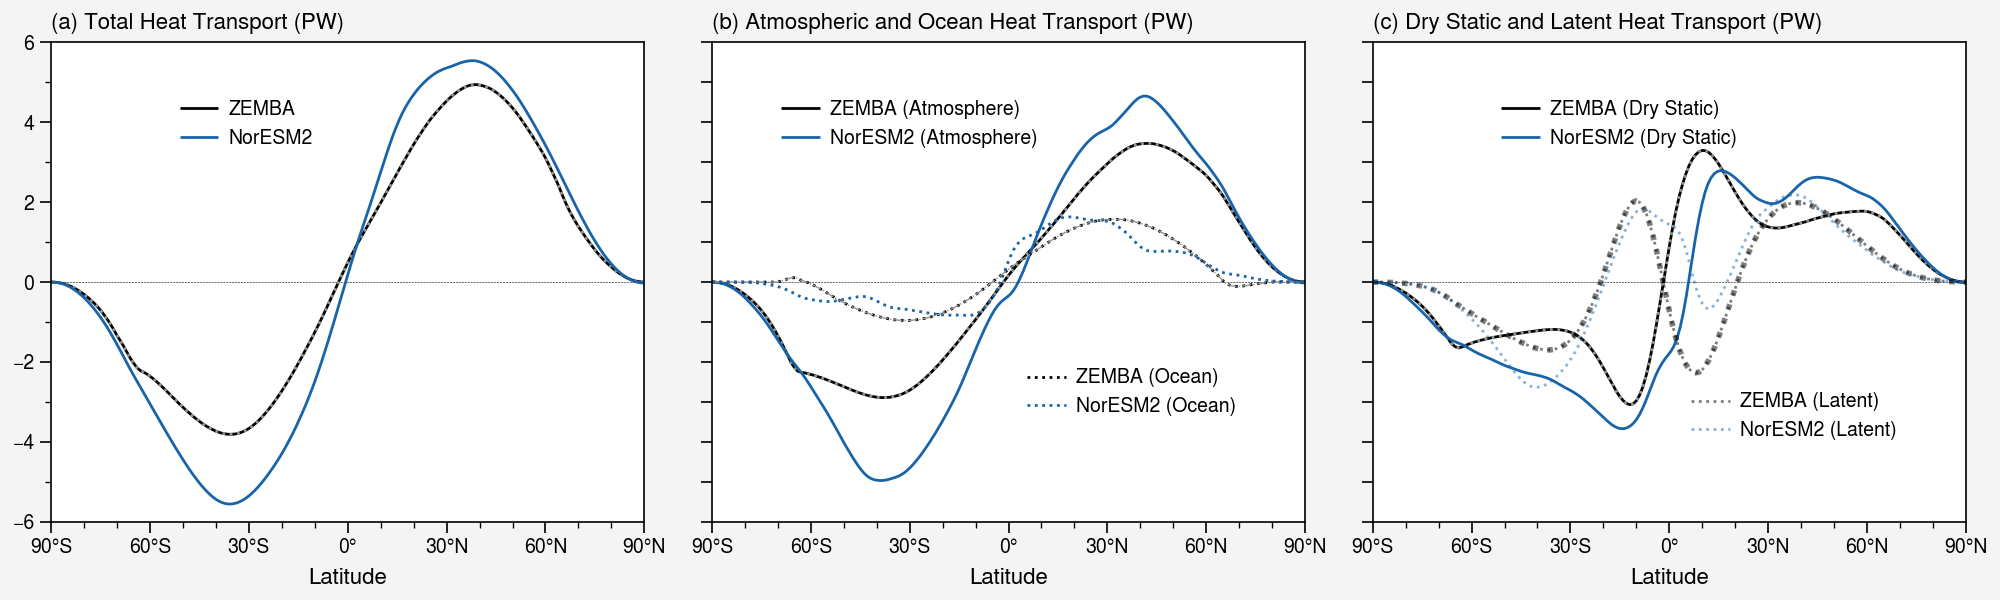

In [8]:
# northward flux of moist static energy in the atmosphere
zemba_atm1 = np.nanmean(pi_01["mse_north"], axis = 1)/1e15
zemba_atm_max_sh1 = -np.min(zemba_atm1[0:int(Var["idxeq"])])
zemba_atm_max_nh1 = np.max(zemba_atm1[int(Var["idxeq"]):])

# northward flux of dry static energy in the atmosphere
zemba_dse1 = np.nanmean(pi_01["dry_north"], axis = 1)/1e15

# northward flux of latent energy in the atmosphere
zemba_latent1 = np.nanmean(pi_01["latent_north"], axis = 1)/1e15

# northward flux of ocean heat
zemba_ocean1 = np.nanmean(pi_01['advf'][0:Var['olatb'].size, :] + pi_01['advf'][Var['olatb'].size*5:Var['olatb'].size*6, :] + pi_01["hdiffs"][0:Var['olatb'].size, :], axis = 1)/1e15 
zemba_ocean1 = np.concatenate((np.zeros((Var["idxnocs"].size)), zemba_ocean1, np.zeros((Var["idxnocn"].size))))
zemba_ocean_max_sh1 = -np.min(zemba_ocean1[0:int(Var["idxeq"])])
zemba_ocean_max_nh1 = np.max(zemba_ocean1[int(Var["idxeq"]):])




# northward flux of moist static energy in the atmosphere
zemba_atm2 = np.nanmean(pi_02["mse_north"], axis = 1)/1e15
zemba_atm_max_sh2 = -np.min(zemba_atm2[0:int(Var["idxeq"])])
zemba_atm_max_nh2 = np.max(zemba_atm2[int(Var["idxeq"]):])

# northward flux of dry static energy in the atmosphere
zemba_dse2 = np.nanmean(pi_02["dry_north"], axis = 1)/1e15

# northward flux of latent energy in the atmosphere
zemba_latent2 = np.nanmean(pi_02["latent_north"], axis = 1)/1e15

# northward flux of ocean heat
nlatb = Var['latb'].size   # 181 at 1°, matches the new advf layout

zemba_ocean2 = np.nanmean(
      pi_02['advf'][0:nlatb, :]                    # layer 0 (surface), full grid
    + pi_02['advf'][5*nlatb : 6*nlatb, :]          # layer 5 (bottom), full grid
    + pi_02['hdiffs'][0:nlatb, :],                 # surface diffusion, full grid
    axis=1) / 1e15

zemba_ocean_max_sh2 = -np.min(zemba_ocean2[0:int(Var["idxeq"])])
zemba_ocean_max_nh2 = np.max(zemba_ocean2[int(Var["idxeq"]):])

#-----------------------------------
# load pre-industrial NorESM2 output
#-----------------------------------

def inferred_heat_transport(energy_in, lat):
    
    '''
    Infers northward heat transport from energy imbalance.
    '''
    
    # load modules
    from scipy import integrate
    
    # latitude in radians
    latr = np.deg2rad(lat)
    
    # cosine of latitude
    coslat = np.cos(latr)
    
    # weighted-mean energy flux
    field = coslat*energy_in
    
    # integral of energy flux for each latitude
    integral = integrate.cumtrapz(field, x=latr, initial=0)
    
    # scale
    result = (1E-15 * 2 * np.math.pi * 6371e3**2 * integral)
    
    return result

# load annual data
noresm2_lat     = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=0)
noresm2_pr      = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=2)
noresm2_prsn    = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=3)
noresm2_evap    = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=4)
noresm2_rsdt    = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=5)
noresm2_rsut    = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=6)
noresm2_rsds    = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=7)
noresm2_rsus    = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=8)
noresm2_rlut    = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=9)
noresm2_rlds    = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=10)
noresm2_rlus    = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=11)
noresm2_shf     = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=12)
noresm2_lhf     = np.loadtxt(input_path+'/other_data/noresm2/noresm2_annual.txt', skiprows=5, usecols=13)

# net radiation at TOA
rtnet_noresm2 = (noresm2_rsdt - noresm2_rsut) - noresm2_rlut

# net radiation at SFC
rsnet_noresm2 = (noresm2_rsds - noresm2_rsus) + (noresm2_rlds - noresm2_rlus)

# net radiation of atmosphere
ratmnet_noresm2 = rtnet_noresm2 - rsnet_noresm2

# upwards sensible heat flux
shf_noresm2 = noresm2_shf

# evaporation latent heat flux 
lhf_noresm2 =  noresm2_evap*2.5e6

# evaporation 
evap_noresm2 =  noresm2_evap

# precipitation 
precip_noresm2 =  noresm2_pr

# precipitation latent heat flux  
precip_latent_noresm2 =  noresm2_pr*2.5e6

# snowfall latent heat flux  
snowfall_latent_noresm2 =  noresm2_prsn*334000

# net heat flux into atmosphere
Fatm_noresm2 = ratmnet_noresm2 + lhf_noresm2 + snowfall_latent_noresm2 + shf_noresm2

# net heat flux into surface
Fs_noresm2 = rsnet_noresm2 - snowfall_latent_noresm2 - shf_noresm2 - lhf_noresm2

# latent heat flux
Flatent_noresm2 = lhf_noresm2 - precip_latent_noresm2  

# total heat transport from TOA energy flux imbalance
noresm2_total = inferred_heat_transport(rtnet_noresm2, noresm2_lat)

# atmospheric heat transport from atmospheric energy flux imbalance
noresm2_atm = inferred_heat_transport(Fatm_noresm2, noresm2_lat)

# ocean heat transport from surface energy flux imbalance
noresm2_ocean = inferred_heat_transport(Fs_noresm2, noresm2_lat)

# latent heat transport in atmosphere from moisture imbalance
noresm2_latent = inferred_heat_transport(Flatent_noresm2, noresm2_lat)

# dry static transport in atmosphereas residual
noresm2_dse = noresm2_atm - noresm2_latent 

# maximum and minimum fluxes
noresm2_ocean_max_sh = -np.min(noresm2_ocean[0:int(noresm2_lat.size/2)])
noresm2_ocean_max_nh = np.max(noresm2_ocean[int(noresm2_lat.size/2):])
noresm2_atm_max_sh   = -np.min(noresm2_atm[0:int(noresm2_lat.size/2)])
noresm2_atm_max_nh   = np.max(noresm2_atm[int(noresm2_lat.size/2):])

#---------
# plotting
#---------

# constants
#----------

zemba_color = "black"
zemba_lw    = 1
zemba_ls    = "-"

noresm_color = "blue9"
noresm_lw    = 1
noresm_ls    = "-"

era5_color = "red9"
era5_lw    = 1
era5_ls    = "-"

legend_fs = 7.

# shape
shape = [  
        [1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3],
        [1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3],
        [1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3],
        [1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3],]

# figure and axes
fig, axs = pplt.subplots(shape, figsize = (10,3), sharey = False, sharex = False, grid = False)


# fonts
axs.format(ticklabelsize=7, ticklabelweight='normal', ylabelsize=8, ylabelweight='normal',
            xlabelsize=8, xlabelweight='normal', titlesize=8, titleweight='normal',)

# x-axis
locatorx      = np.arange(-90, 120, 30)
minorlocatorx = np.arange(-90, 100, 10)
axs.format(xminorlocator = minorlocatorx, xlocator = locatorx, xlim = (-90, 90))
axs.format(xlabel = "Latitude", xformatter='deglat')   

# format top left subplot
for i in np.arange(0,1):
    
    # y-axis
    axs[i].format(ylim = (-6, 6), yminorlocator=np.arange(-6, 6+1, 1), ylocator = np.arange(-6, 6+2, 2))
    
    # hline
    axs[i].axhline(0, Var["lat"].min(), Var["lat"].max(), color = "black", lw = 0.2, linestyle ="--")
      
# format middle plot
for i in np.arange(1,2):
    
    # y-axis
    axs[i].format(ylim = (-6, 6), yminorlocator=[], ylocator = np.arange(-6, 6+1, 1))
    axs[i].yaxis.set_ticklabels([])
    
    # hline
    axs[i].axhline(0, Var["lat"].min(), Var["lat"].max(), color = "black", lw = 0.2, linestyle ="--")
    
# format right plot
for i in np.arange(2,3):
    
    # y-axis
    axs[i].format(ylim = (-6, 6), yminorlocator=[], ylocator = np.arange(-6, 6+1, 1))
    axs[i].yaxis.set_ticklabels([])
    
    # hline
    axs[i].axhline(0, Var["lat"].min(), Var["lat"].max(), color = "black", lw = 0.2, linestyle ="--")
    
# titles
axs[0].format(title = r'(a) Total Heat Transport (PW)', titleloc = 'left')
axs[1].format(title = r'(b) Atmospheric and Ocean Heat Transport (PW)', titleloc = 'left')
axs[2].format(title = r'(c) Dry Static and Latent Heat Transport (PW)', titleloc = 'left')

# plot total heat transport
#--------------------------

zemba_total_line    = axs[0].plot(Var["latb"], zemba_atm1 + zemba_ocean1, color = zemba_color, lw = zemba_lw, ls = zemba_ls)
axs[0].plot(Var["latb"], zemba_atm2 + zemba_ocean2, color = 'gray', lw = zemba_lw, ls = ':')
noresm_total_line = axs[0].plot(noresm2_lat, noresm2_total, color = noresm_color, lw = noresm_lw, ls = noresm_ls)

# legend
axs[0].legend(handles = [zemba_total_line, noresm_total_line],
              labels  = ["ZEMBA", "NorESM2"], 
                          frameon = False, loc = "ul", bbox_to_anchor=(0.2, 0.9), 
                          ncols = 1, prop={'size':legend_fs})


# plot atmospheric + ocean
#-------------------------

zemba_atm_line = axs[1].plot(Var["latb"], zemba_atm1, color = zemba_color, lw = zemba_lw, ls = zemba_ls)
axs[1].plot(Var["latb"], zemba_atm2, color = 'gray', lw = zemba_lw, ls = ':')
noresm_atm_line = axs[1].plot(noresm2_lat, noresm2_atm, color = noresm_color, lw = noresm_lw, ls = noresm_ls)
zemba_ocean_line = axs[1].plot(Var["latb"], zemba_ocean1, color = zemba_color, lw = zemba_lw, ls = ":")
axs[1].plot(Var["latb"], zemba_ocean2, color = 'gray', lw = 0.5, ls = "-.")
noresm_ocean_line = axs[1].plot(noresm2_lat, noresm2_ocean, color = noresm_color, lw = noresm_lw, ls = ":")

# legend
axs[1].legend(handles = [zemba_atm_line, noresm_atm_line],
              labels  = ["ZEMBA (Atmosphere)", "NorESM2 (Atmosphere)"], 
                          frameon = False, loc = "ul", bbox_to_anchor=(0.1, 0.9), 
                          ncols = 1, prop={'size':legend_fs})

# legend
axs[1].legend(handles = [zemba_ocean_line, noresm_ocean_line],
              labels  = ["ZEMBA (Ocean)", "NorESM2 (Ocean)"], 
                          frameon = False, loc = "lr", bbox_to_anchor=(0.9, 0.2), 
                          ncols = 1, prop={'size':legend_fs})

# plot atmospheric partition
#---------------------------

zemba_dse_line       = axs[2].plot(Var["latb"], zemba_dse1, color = zemba_color, lw = zemba_lw, ls = zemba_ls)
axs[2].plot(Var["latb"], zemba_dse2, color = 'gray', lw = zemba_lw, ls = ':')
noresm_dse_line    = axs[2].plot(noresm2_lat, noresm2_dse, color = noresm_color, lw = noresm_lw, ls = noresm_ls)
zemba_latent_line    = axs[2].plot(Var["latb"], zemba_latent1, color = zemba_color, lw = zemba_lw, ls = ":", alpha = 0.5)
axs[2].plot(Var["latb"], zemba_latent2, color = zemba_color, lw = 2, ls = ":", alpha = 0.5)
noresm_latent_line = axs[2].plot(noresm2_lat, noresm2_latent, color = noresm_color, lw = noresm_lw, ls = ":", alpha = 0.5)

# legend
axs[2].legend(handles = [zemba_dse_line, noresm_dse_line],
              labels  = ["ZEMBA (Dry Static)", "NorESM2 (Dry Static)"], 
                          frameon = False, loc = "ul", bbox_to_anchor=(0.2, 0.9), 
                          ncols = 1, prop={'size':legend_fs})

# legend
axs[2].legend(handles = [zemba_latent_line, noresm_latent_line,],
              labels  = ["ZEMBA (Latent)","NorESM2 (Latent)"], 
                          frameon = False, loc = "lr", bbox_to_anchor=(0.9, 0.15), 
                          ncols = 1, prop={'size':legend_fs})
print('###########################')
print("Peak Atmospheric Heat Transport....")
print('###########################')

print("pyzemba (SH): " + str(round(zemba_atm_max_sh1, 2)))
print("pyzemba (NH): " + str(round(zemba_atm_max_nh1, 2)))

print("pyzemba2 (SH): " + str(round(zemba_atm_max_sh2, 2)))
print("pyzemba2 (NH): " + str(round(zemba_atm_max_nh2, 2)))

print("NorESM2 (SH): " + str(round(noresm2_atm_max_sh, 2)))
print("NorESM2 (NH): " + str(round(noresm2_atm_max_nh, 2))+'\n')

# print("ERA5 (SH): " + str(round(era5_atm_max_sh, 2)))
# print("ERA5 (NH): " + str(round(era5_atm_max_nh, 2)))

print('###########################')
print("Peak Ocean Heat Transport....")
print('###########################')

print("pyzemba (SH): " + str(round(zemba_ocean_max_sh1, 2)))
print("pyzemba (NH): " + str(round(zemba_ocean_max_nh1, 2)))

print("pyzemba2 (SH): " + str(round(zemba_ocean_max_sh2, 2)))
print("pyzemba2 (NH): " + str(round(zemba_ocean_max_nh2, 2)))


print("NorESM2 (SH): " + str(round(noresm2_ocean_max_sh, 2)))
print("NorESM2 (NH): " + str(round(noresm2_ocean_max_nh, 2))+'\n')

# print("ERA5 (SH): " + str(round(era5_ocean_max_sh, 2)))
# print("ERA5 (NH): " + str(round(era5_ocean_max_nh, 2)))